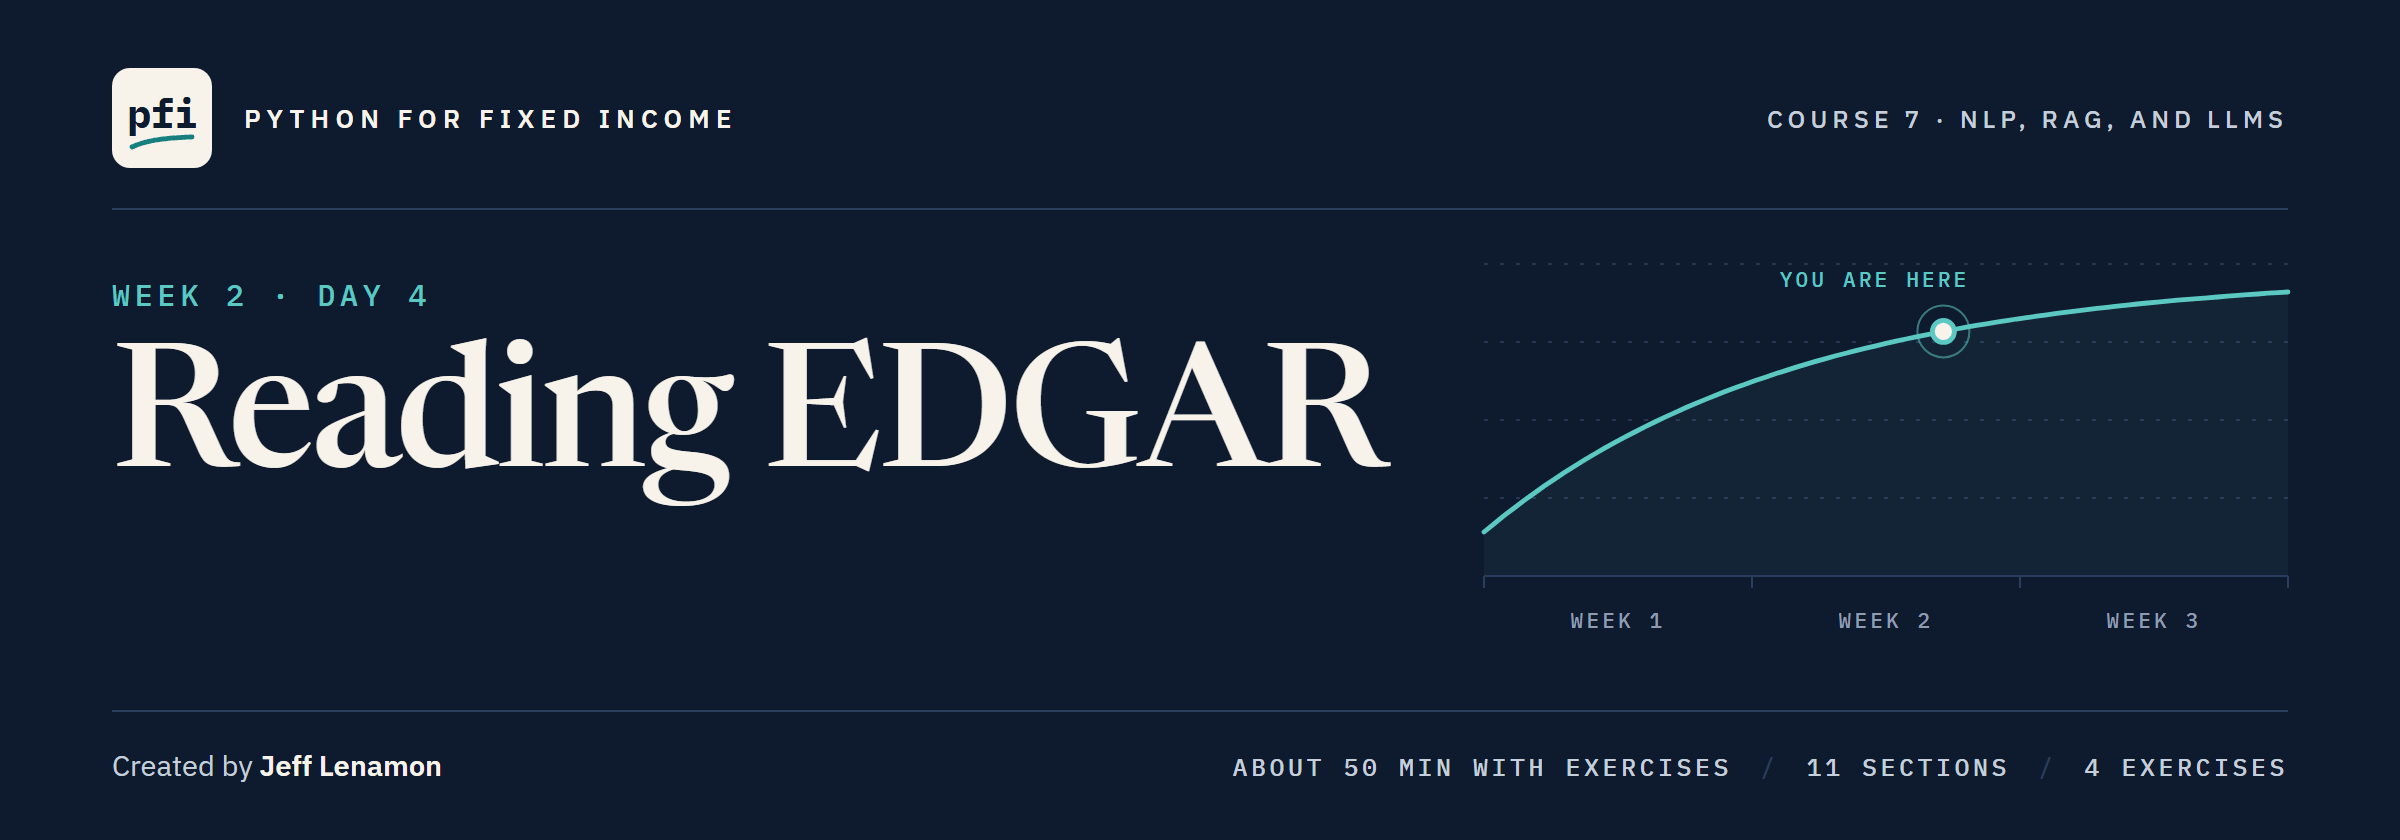

# Reading EDGAR

Week 2, Day 4. Take a filing from EDGAR to text a program can count: ask within the SEC's rules, keep the words, and cut at the headings.

**Data:** `course7_boyd_10k_2025.htm`: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908: **real**, a public record on sec.gov, quoted for descriptive extraction only.

**Data:** `course7_indentures/boyd_2021.txt`: Boyd Gaming Corporation, Indenture dated as of June 8, 2021, 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495: **real**, a public record on sec.gov, quoted for descriptive extraction only.

**Data:** `course7_8k_items.csv`, 5,126 item sections of Form 8-K current reports filed on EDGAR, 2019 to 2025, each labelled by the item its filer chose: **real**, public records (sec.gov), a sample drawn by the course (DATA.md).

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week2/day4/09_reading_edgar.ipynb)

# Problem Statement

## Business Context

A credit desk reads EDGAR every day: annual reports, 8-Ks, and indentures filed as exhibits.
Days 1 to 8 read the course's copies; today shows how a copy is made, and checks it.
The documents are Boyd's Form 10-K for fiscal 2025 as filed, the Boyd indenture's exhibit as filed, and one 2022 filing from Day 3's 8-K file.
They are real public documents, quoted for description only: a size or a word count describes how a filer wrote a document, never the filer.
Nothing is sent to sec.gov: the request code runs against a stand-in.
Nothing is fitted, so nothing is split, and the 2025 sections stay closed until Day 10.

## Objectives

Build EDGAR's addresses from a CIK and an accession number.
Declare who you are and keep under the SEC's request rate, in code.
Test a fetch function on a stand-in session.
Turn a filing's HTML into one paragraph per line, without inline XBRL's hidden header.
Cut a 10-K and an 8-K at headings that start a line.
Check a stored text against the document it came from.

## Data Dictionary

`course7_boyd_10k_2025.htm`: Boyd's Form 10-K for the fiscal year ended 2025-12-31, filed 2026-02-20, as filed (HTML with inline XBRL).

`course7_indentures/boyd_2021.htm`: the Boyd indenture as filed, Exhibit 4.1 to an 8-K; `boyd_2021.txt` is the text Day 1 read.

`course7_8k_items.csv`: Day 3's file, one row per item section; one 2022 filing is read.

Made in the notebook: `ten_k_text`, `items` (columns `item`, `start`, `end`, `text`, `words`) and `exhibit_text`.

## Your Route Through Day 4

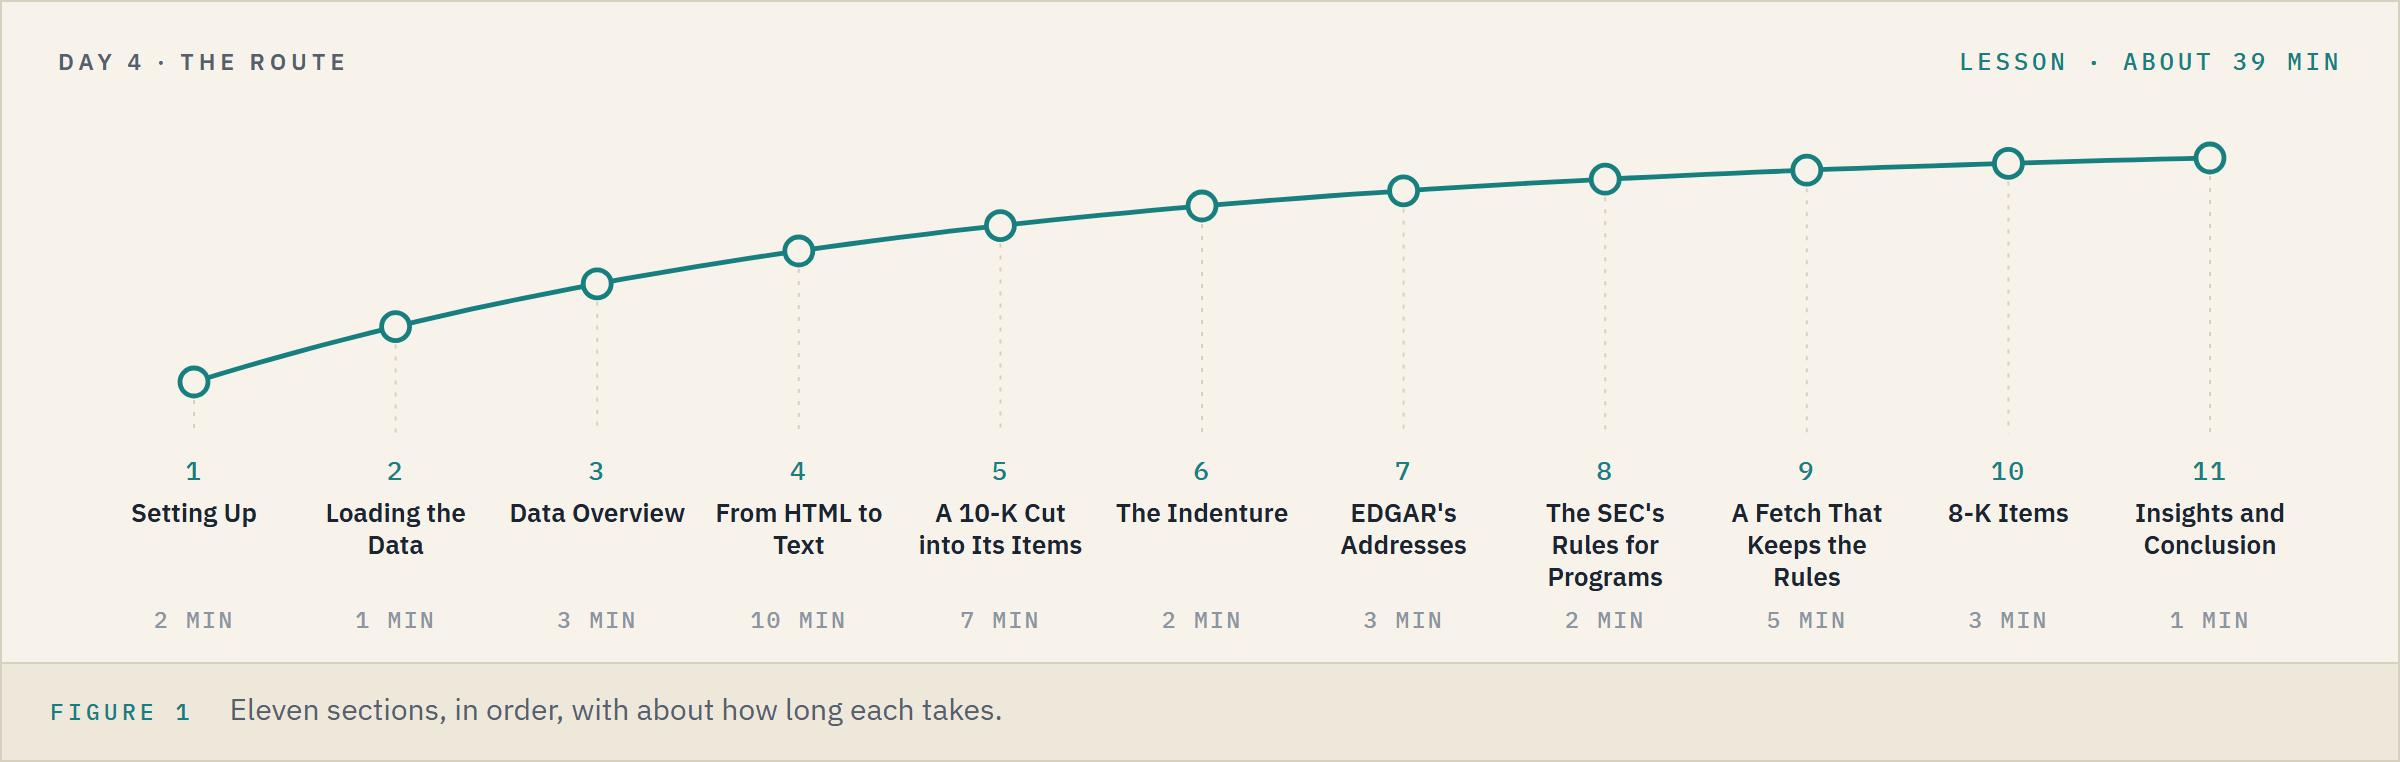

**Time.** About 39 minutes for the lesson, then about 12 for the four exercises.

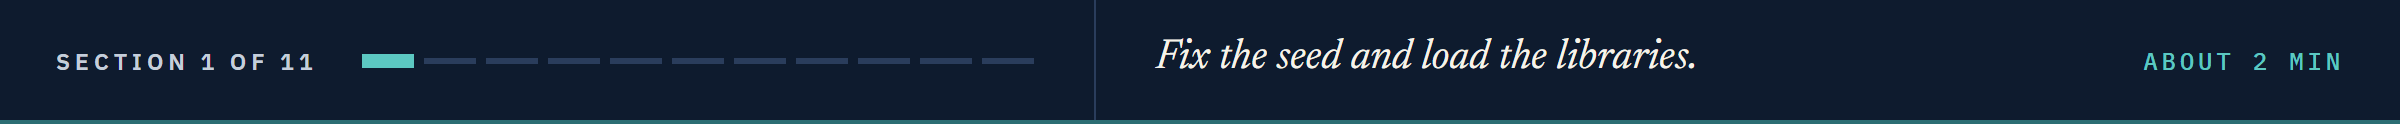

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text and addresses: regular expressions, Unicode names, a counter, the pause between requests, URL quoting
import re
import time
import unicodedata
from collections import Counter
from urllib.parse import quote

# HTTP and HTML: requests sends a request (never in this notebook), BeautifulSoup reads a page
import requests
from bs4 import BeautifulSoup, NavigableString

# data, charts and a dropdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

Day 1's data-file cell, unchanged: the repo's path on your machine, a copy downloaded once in Colab.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

## Day 1's Pieces in One Cell

Day 1's `normalize_text` and source lines, repeated, with the 10-K's in the same form.

In [4]:
# Day 1's map of look-alike characters and normalize_text, unchanged
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


# the source lines: the 10-K (with an item when there is one), Day 1's indenture, Day 3's 8-K section
def tenk_source(item=None):
    """Print the source line of the Boyd 10-K, or of one of its items."""
    where = f", Item {item}" if item else ""
    print("Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, "
          f"accession 0001437749-26-004908{where}.")


def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")


def section_source(row):
    """Print the source line of one 8-K section."""
    print(f"Source: {row['company']}, Form 8-K filed {row['filed']}, accession {row['accession']}, Item {row['item']}, {row['url']}")

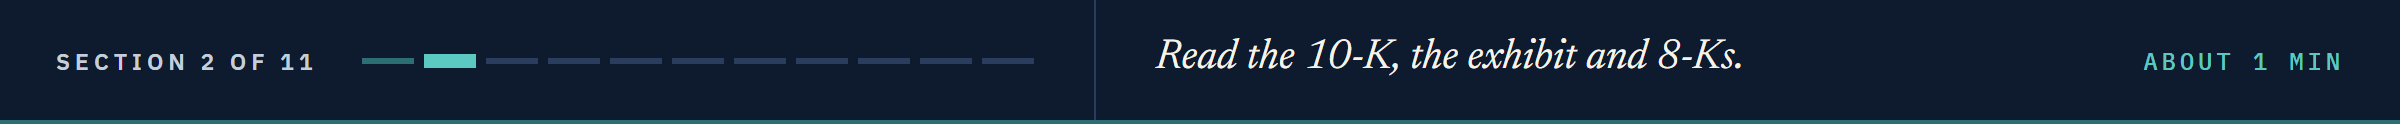

# Loading the Data

## The 10-K as Filed

`Path.read_bytes()` reads a file as **bytes**, the numbers 0 to 255 a file is stored as, without turning them into characters.

In [5]:
# the 10-K as the filer's bytes
ten_k_bytes = Path(data_file("course7_boyd_10k_2025.htm")).read_bytes()
len(ten_k_bytes)

4008734

## The Exhibit, Its Text and the 8-K Sections

An indenture reaches EDGAR as an **exhibit**, a document attached to a filing: the Boyd indenture is Exhibit 4.1 to an 8-K.

In [6]:
# the exhibit as filed, the text Day 1 read, and Day 3's 8-K file with the item codes as text
exhibit_bytes = Path(data_file("course7_indentures/boyd_2021.htm")).read_bytes()
stored = Path(data_file("course7_indentures/boyd_2021.txt")).read_text(encoding="utf-8")
eightk = pd.read_csv(DATA + "course7_8k_items.csv", dtype={"item": str})
print(len(exhibit_bytes), "bytes as filed |", len(stored), "characters in the .txt |", eightk.shape)

872436 bytes as filed | 392021 characters in the .txt | (5126, 9)


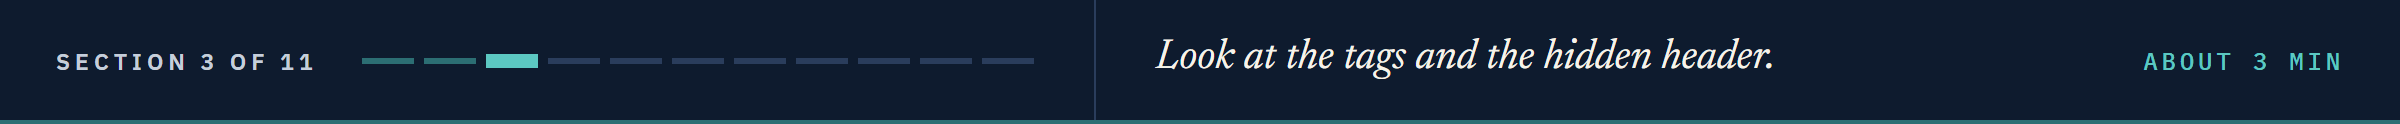

# Data Overview

## The First Bytes

A web page is **HTML**: text with **tags** in angle brackets, such as `<p>` before a paragraph and `</p>` after it.
`b'...'` marks bytes when Python prints them.

In [7]:
# source text: quoted as published
# the first 200 bytes of the 10-K
print(ten_k_bytes[:200])
tenk_source()

b'<?xml version=\'1.0\' encoding=\'ASCII\'?>\n<html xmlns="http://www.w3.org/1999/xhtml" xmlns:ref="http://www.xbrl.org/2006/ref" xmlns:xbrldi="http://xbrl.org/2006/xbrldi" xmlns:naics="http://xbrl.sec.gov/n'
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.


The page opens as XML and names XBRL's namespaces, such as `xmlns:xbrldi`.

So this 10-K is **inline XBRL**: an HTML page whose numbers are also tagged as facts a program can read.

## Every Tag in the 10-K

`BeautifulSoup(raw, "html.parser")` reads a page into a tree of tags with Python's own parser, so nothing more is installed.
`soup.find_all(True)` returns every tag in the tree.

35027 tags | 47 names


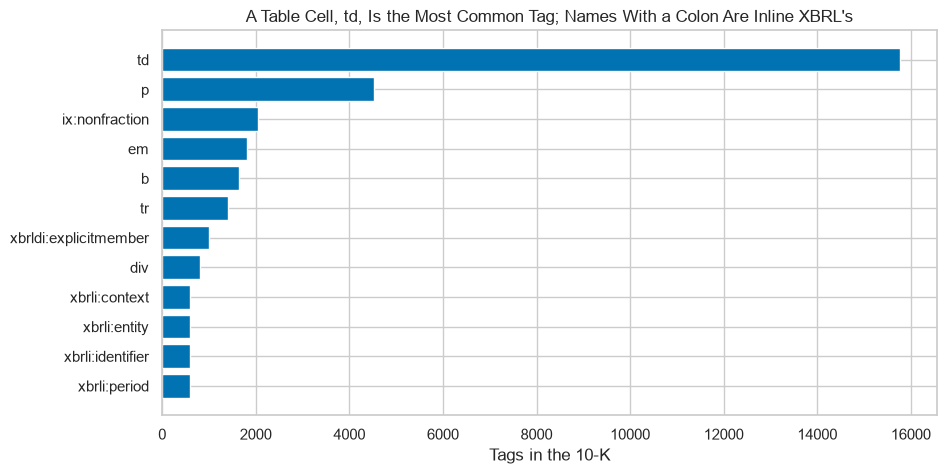

In [8]:
# the page as a tree of tags, every tag in it, and the twelve most common names
soup = BeautifulSoup(ten_k_bytes, "html.parser")
names = Counter(tag.name for tag in soup.find_all(True))
print(sum(names.values()), "tags |", len(names), "names")
top = pd.Series(dict(names.most_common(12))).sort_values()
plt.barh(top.index, top.values)
plt.xlabel("Tags in the 10-K")
plt.title("A Table Cell, td, Is the Most Common Tag; Names With a Colon Are Inline XBRL's")
plt.show()

`td`, a table cell, comes first: the financial statements are tables, one cell a figure.

`ix:nonfraction` tags a number as a fact; `xbrli:` tags describe the facts.

## The Hidden Header

`ix:header` holds the facts of the cover in a block the reader never sees.
`bytes.find(b"...")` returns where a run of bytes starts; a tag's `.find(name)` returns its first tag of that name, and `.get_text(" ")` every piece of text inside it, joined by a space.

In [9]:
# source text: quoted as published
# where the hidden header starts and ends in the file, and its share of the file
header_start = ten_k_bytes.find(b"<ix:header")
header_end = ten_k_bytes.find(b"</ix:header>") + len(b"</ix:header>")
print(header_start, "to", header_end, "|", header_end - header_start, "bytes |", round((header_end - header_start) / len(ten_k_bytes), 4), "of the file")

# the tagged facts in the whole page and in the header, then the header's first six pieces of text
header = soup.find("ix:header")
facts = ["ix:nonfraction", "ix:nonnumeric"]
print(len(soup.find_all(facts)), "tagged facts |", len(header.find_all(facts)), "in the header |", header.get_text(" ").split()[:6])
tenk_source()

2024 to 389317 | 387293 bytes | 0.0966 of the file
2296 tagged facts | 118 in the header | ['0000906553', 'BOYD', 'GAMING', 'CORP', 'false', '--12-31']
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.


The header holds 387,293 bytes, and 118 of the page's 2,296 tagged facts.

Its first pieces are Boyd's CIK, the filer's name, a flag and the fiscal year's end.

**Four megabytes of markup and tagged facts: before any word is counted, the words come out.**

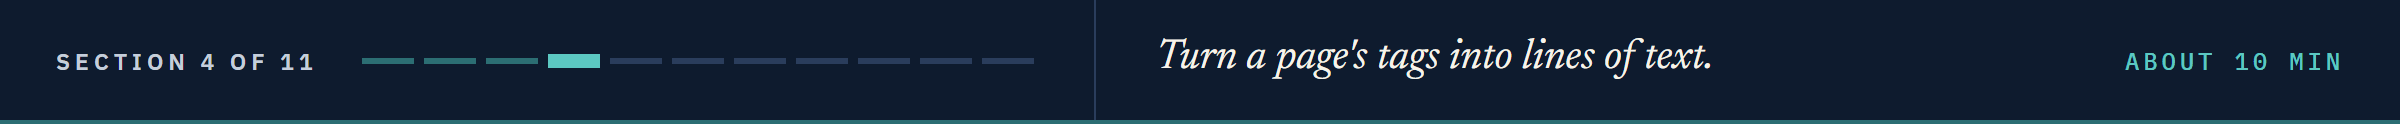

# From HTML to Text

**Predict 1**

Q. The 10-K is 4,008,734 bytes. How many characters of readable text does it hold, one paragraph per line? Write down a number.

## `get_text` Alone

In [10]:
# source text: quoted as published
# every piece of text in the page, through normalize_text: its size, its start, and one passage counted
plain = normalize_text(soup.get_text())
print(len(plain), "characters |", plain.count("\n") + 1, "lines")
print(plain[:160])
print('"Cybersecurity represents a critical component" appears', plain.count("Cybersecurity represents a critical component"), "times")
tenk_source()

478405 characters | 4508 lines
bgc20251121_10k.htm
0000906553
BOYD GAMING CORP
false
--12-31
FY
2025
Cybersecurity represents a critical component of the Company's overall approach to risk ma
"Cybersecurity represents a critical component" appears 2 times
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.


The text opens with the header's facts, before the cover.

The cybersecurity passage appears twice: once as a tagged fact in the header, once in the text.

**Drop the header first, then keep the words.**

## How a Page Becomes Lines

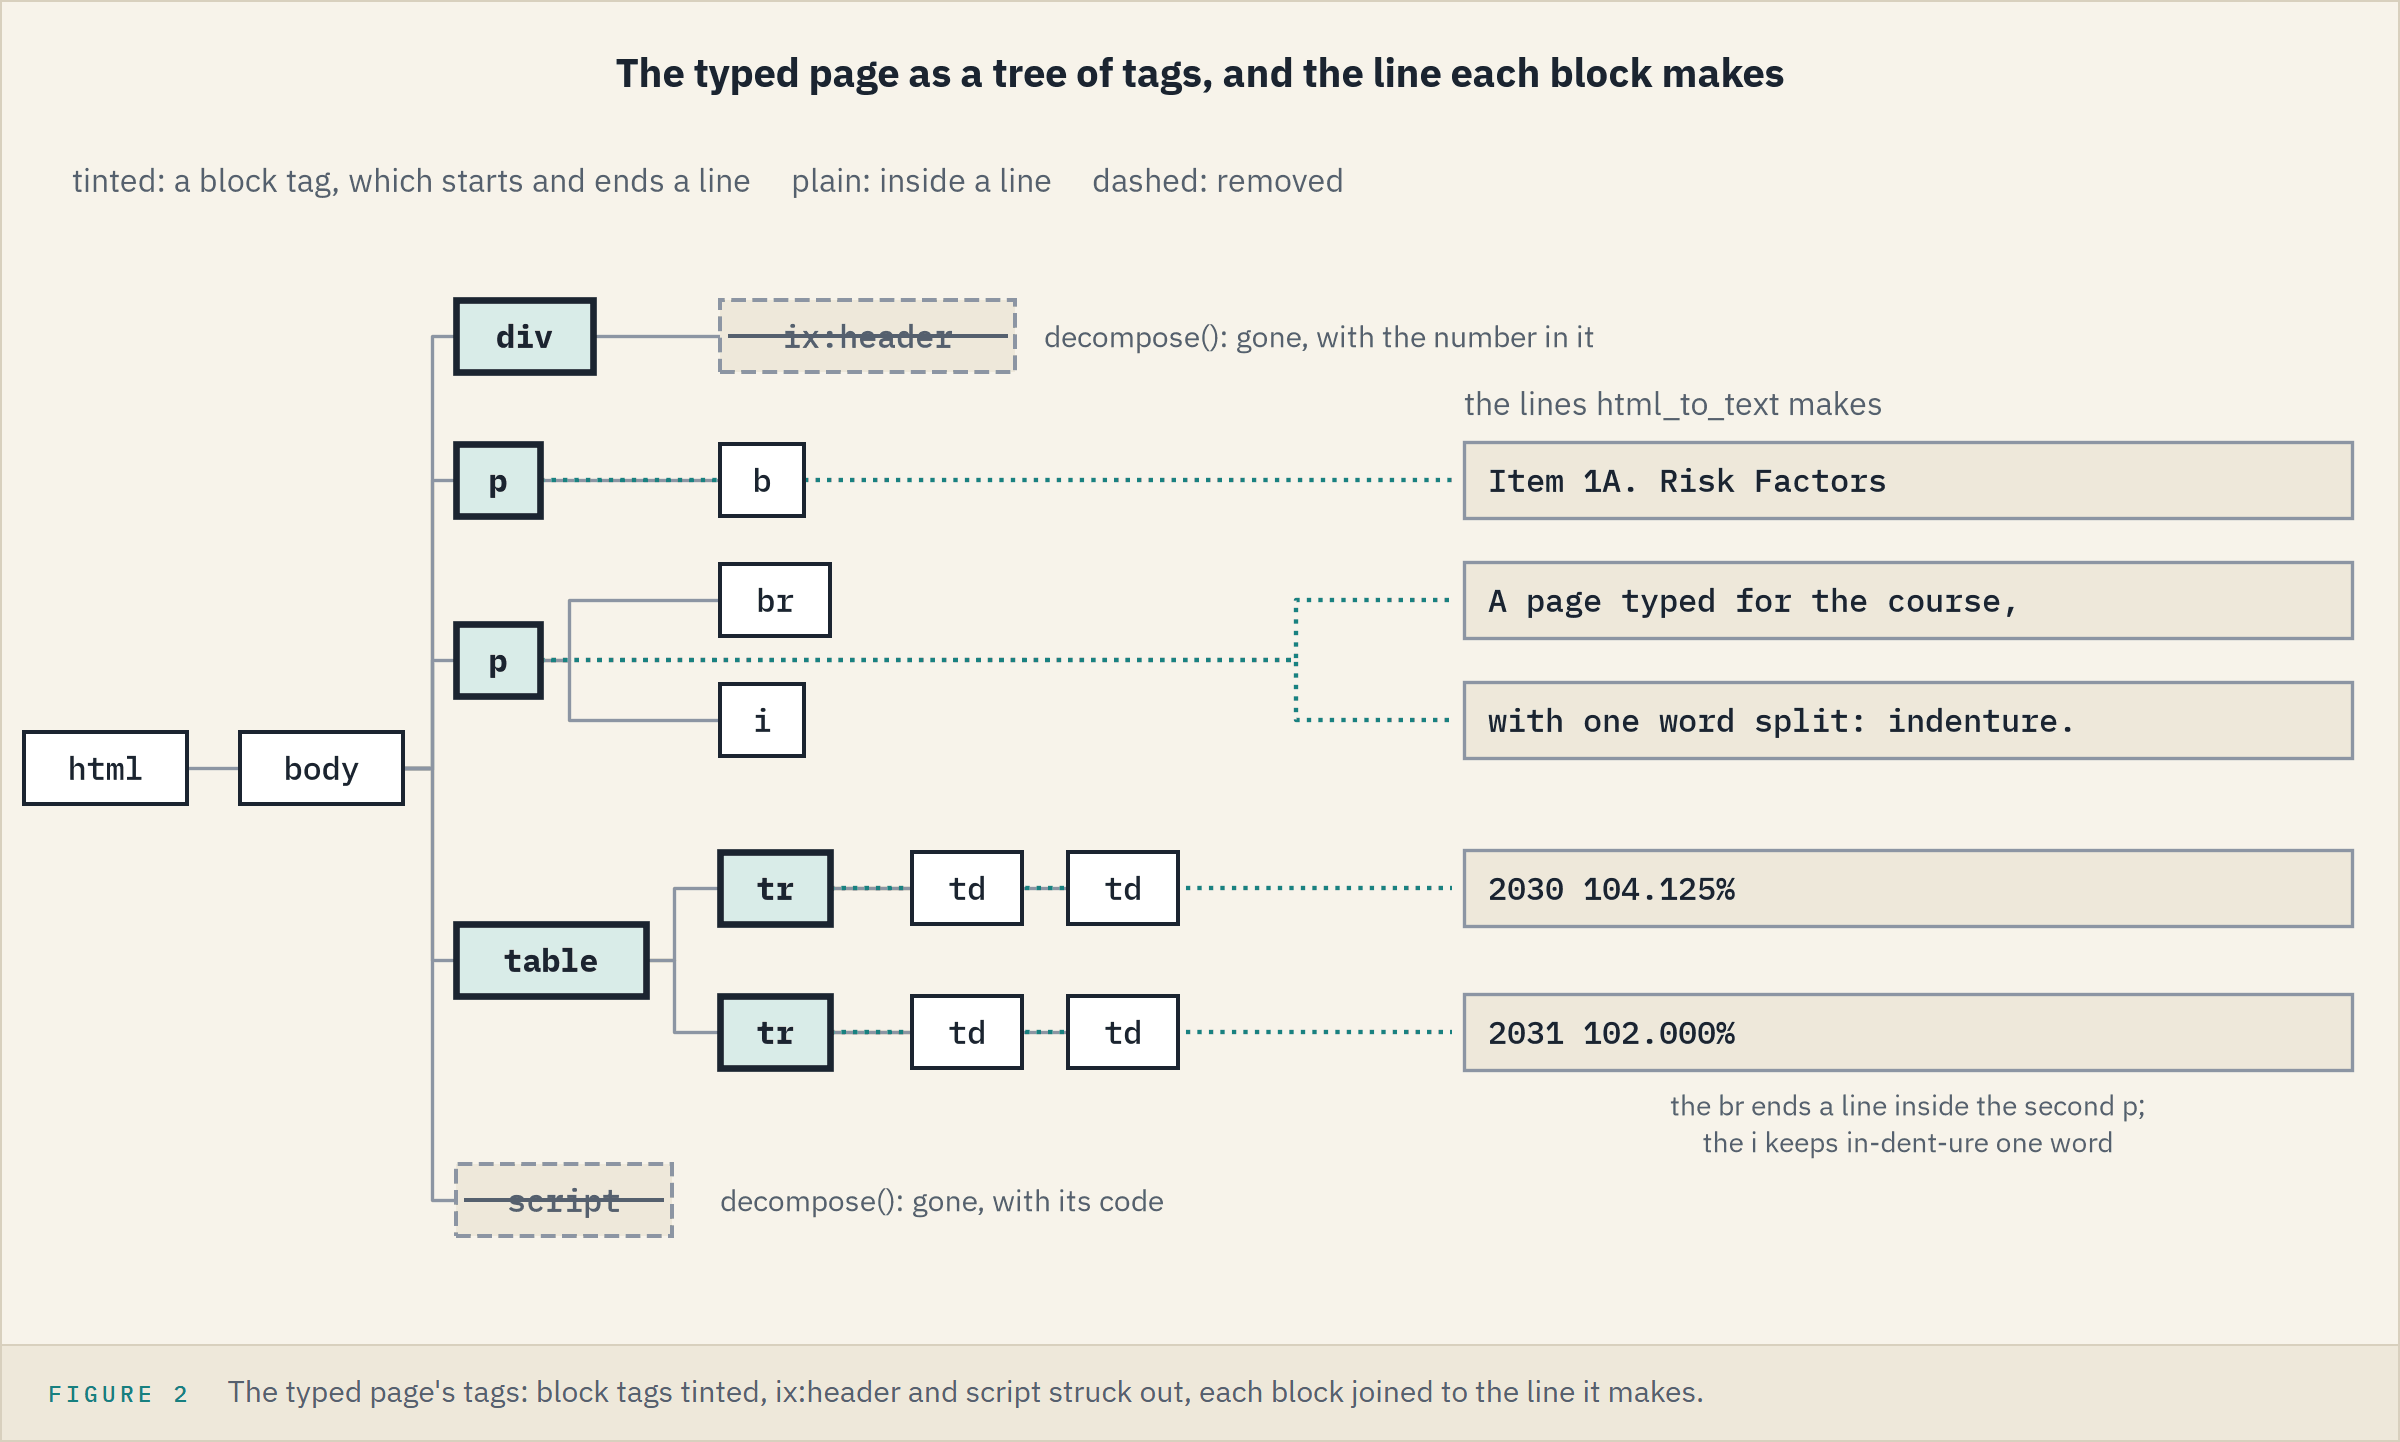

A page typed for the course shows each step; its source breaks one sentence across two lines, as filers' HTML often does.

In [11]:
# a typed page: a hidden header, a heading, a paragraph with a line break and a word split by a tag, a table, a script
PAGE = ("<html><body><div><ix:header>0000123456 SAMPLE PAGE</ix:header></div>"
        "<p><b>Item 1A.</b> Risk Factors</p><p>A page typed for the course,<br>with one word\n      split: in<i>dent</i>ure.</p>"
        "<table><tr><td>2030</td><td>104.125%</td></tr><tr><td>2031</td><td>102.000%</td></tr></table>"
        "<script>var shown = false;</script></body></html>")
print(len(PAGE), "characters")
print(repr(BeautifulSoup(PAGE, "html.parser").get_text()))

328 characters
'0000123456 SAMPLE PAGEItem 1A. Risk FactorsA page typed for the course,with one word\n      split: indenture.2030104.125%2031102.000%'


`get_text` alone runs the blocks together, keeps the source's line break inside the sentence, and keeps the header's number.

### Step 1: Remove the Header and the Script

A tag's `.decompose()` removes it from the tree with everything inside it.

In [12]:
# the hidden header and the script, removed with everything inside them
demo = BeautifulSoup(PAGE, "html.parser")
for tag in demo.find_all(["ix:header", "script"]):
    tag.decompose()
print(repr(demo.get_text()))

'Item 1A. Risk FactorsA page typed for the course,with one word\n      split: indenture.2030104.125%2031102.000%'


### Step 2: White Space Inside Text

`find_all(string=True)` returns every piece of text, and `.replace_with(new)` swaps a piece for another.

In [13]:
# every run of white space inside a piece of text becomes one space
# (type(node) is NavigableString keeps plain text only: a comment in the HTML is a piece of text too, and is skipped)
for node in demo.find_all(string=True):
    if type(node) is NavigableString:
        node.replace_with(re.sub(r"\s+", " ", str(node)))
print(repr(demo.get_text()))

'Item 1A. Risk FactorsA page typed for the course,with one word split: indenture.2030104.125%2031102.000%'


### Step 3: A Line Break

`<br>` is a line break, and a tag's `.find_parent(names)` returns the nearest tag around it with one of those names.

In [14]:
# a <br> becomes a newline, or a space inside a table cell
for tag in demo.find_all("br"):
    tag.replace_with(" " if tag.find_parent(["td", "th"]) else "\n")
print(repr(demo.get_text()))

'Item 1A. Risk FactorsA page typed for the course,\nwith one word split: indenture.2030104.125%2031102.000%'


### Step 4: A Block Starts and Ends a Line

A **block tag**, such as `p`, `div` or `tr`, starts and ends a line; an **inline tag**, such as `b` or `i`, stays inside the line.
`.insert_before(x)` puts `x` just before a tag, and a tag's `.append(x)` puts `x` at the end of its inside (Course 1's `.append` was a list's).

In [15]:
# the 21 tags that start and end a line of text, each given a newline before and after
BLOCK_TAGS = ["p", "div", "h1", "h2", "h3", "h4", "h5", "h6", "li", "ul", "ol", "table", "tr", "section",
              "article", "blockquote", "pre", "center", "title", "dt", "dd"]
for tag in demo.find_all(BLOCK_TAGS):
    tag.insert_before("\n")
    tag.append("\n")
print(normalize_text(demo.get_text()))

Item 1A. Risk Factors
A page typed for the course,
with one word split: indenture.
2030104.125%
2031102.000%


Every block is a line now, but each row's two cells run together: 2030104.125%.

### Step 5: A Table Cell

In [16]:
# a table cell ends with a space, so a row's cells stay apart
for cell in demo.find_all(["td", "th"]):
    cell.append(" ")
print(normalize_text(demo.get_text()))

Item 1A. Risk Factors
A page typed for the course,
with one word split: indenture.
2030 104.125%
2031 102.000%


## `html_to_text`

The five steps in one function, plus one piece: a block inside a table cell ends with a space, so a cell stays one piece of text.

In [17]:
# the header and scripts removed, white space made one space, then line breaks, table cells and blocks, then Day 1's normalize_text
def html_to_text(html):
    """The readable text of an HTML document, one paragraph per line."""
    soup = BeautifulSoup(html, "html.parser")
    for tag in soup.find_all(["script", "style", "ix:header"]):
        tag.decompose()
    for node in soup.find_all(string=True):
        if type(node) is NavigableString:
            node.replace_with(re.sub(r"\s+", " ", str(node)))
    for tag in soup.find_all("br"):
        tag.replace_with(" " if tag.find_parent(["td", "th"]) else "\n")
    for cell in soup.find_all(["td", "th"]):
        for tag in cell.find_all(BLOCK_TAGS):
            tag.insert_before(" ")
            tag.append(" ")
        cell.append(" ")
    for tag in soup.find_all(BLOCK_TAGS):
        if tag.name in ("tr", "table") or not tag.find_parent(["td", "th"]):
            tag.insert_before("\n")
            tag.append("\n")
    return normalize_text(soup.get_text())


print(html_to_text(PAGE))

Item 1A. Risk Factors
A page typed for the course,
with one word split: indenture.
2030 104.125%
2031 102.000%


The five lines of Picture 1, with "indenture" one word across its `i` tag.

## The 10-K as Text

sec.gov's delivery network adds one `<script>` tag to every document it serves (the repo's `DATA.md`), so the cell tries a copy with one such tag, typed for the course.

In [18]:
# the 10-K through html_to_text: characters, words, lines and the share of the file's bytes
ten_k_text = html_to_text(ten_k_bytes)
print(len(ten_k_text), "characters |", len(ten_k_text.split()), "words |", ten_k_text.count("\n") + 1, "lines |",
      round(len(ten_k_text) / len(ten_k_bytes), 4), "of the bytes")
print("the cybersecurity passage:", ten_k_text.count("Cybersecurity represents a critical component"),
      "time | the CIK 0000906553 among the words:", ten_k_text.split().count("0000906553"), "times")

# a copy as sec.gov serves it, a typed script tag before </body>: the same text?
served = ten_k_bytes.replace(b"</body>", b'<script src="/delivery.js"></script></body>', 1)
print(len(served) - len(ten_k_bytes), "bytes more | the same text:", html_to_text(served) == ten_k_text)

422118 characters | 65067 words | 2583 lines | 0.1053 of the bytes
the cybersecurity passage: 1 time | the CIK 0000906553 among the words: 0 times
36 bytes more | the same text: True


422,118 characters, 10.5 percent of the file: the rest is markup and the header.

The passage appears once, the CIK only the header held is gone, and a served copy gives the same text.

`str.encode("utf-8")` turns text into bytes, so the text is measured in the file's unit.
**Part-in-whole area circles** draw each part as a circle inside the whole, its area its size.

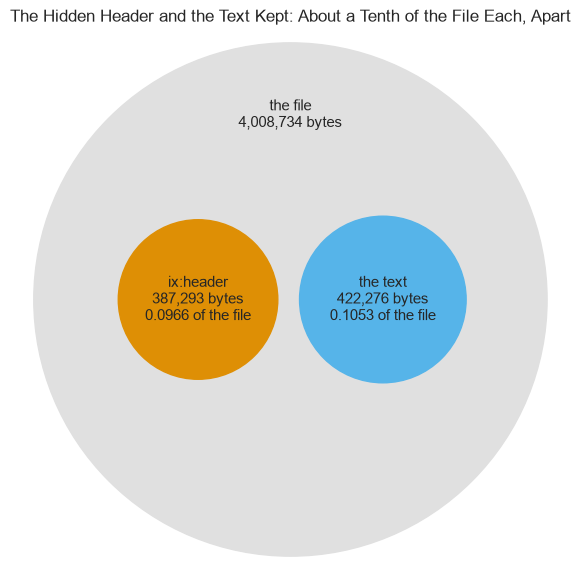

In [19]:
# the file, the header and the text as circles whose areas are their bytes (the text measured as UTF-8 bytes)
sizes = {"the file": len(ten_k_bytes), "ix:header": header_end - header_start, "the text": len(ten_k_text.encode("utf-8"))}
fig, ax = plt.subplots(figsize=(7, 7))
for (name, size), (x, y), colour in zip(sizes.items(), [(0, 0.72), (-0.36, 0), (0.36, 0)], ["0.88", "C1", "C9"]):
    ax.add_patch(plt.Circle((0, 0) if name == "the file" else (x, y), np.sqrt(size / sizes["the file"]), color=colour))
    share = "" if name == "the file" else f"\n{size / sizes['the file']:.4f} of the file"
    ax.text(x, y, f"{name}\n{size:,} bytes{share}", ha="center", va="center", fontsize=11)
ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), aspect="equal")
ax.set_axis_off()
ax.set_title("The Hidden Header and the Text Kept: About a Tenth of the File Each, Apart")
plt.show()

`plt.Circle((x, y), r)` makes a circle and `ax.add_patch` draws it; a radius of the square root of the share makes the area the share.

The two circles do not touch: none of the header is in the text.

## The Start of the Text

`ascii(text)` writes each character outside ASCII as an escape made of plain characters.

In [20]:
# source text: quoted as published
# the first 300 characters of the text
print(ten_k_text[:300])
tenk_source()

# the characters above 127, by code point and name, then the one ligature in a short window
for ch, times in Counter(ch for ch in ten_k_text if ord(ch) > 127).most_common():
    print(f"U+{ord(ch):04X}", unicodedata.name(ch), times)
ligature = ten_k_text.find(chr(0xFB03))
print(ligature, ascii(ten_k_text[ligature - 20:ligature + 10]))

bgc20251121_10k.htm
Table of Contents
UNITED STATES
SECURITIES AND EXCHANGE COMMISSION
WASHINGTON, D.C. 20549
FORM 10-K
(Mark One)
☒ ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934
For the fiscal year ended December 31, 2025
OR
☐ TRANSITION REPORT PURSUANT TO SEC
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.
U+2022 BULLET 51
U+2610 BALLOT BOX 13
U+2612 BALLOT BOX WITH X 8
U+00A7 SECTION SIGN 4
U+25CF BLACK CIRCLE 4
U+FB03 LATIN SMALL LIGATURE FFI 1
3506 "strant's executive o\ufb03cers duri"


The file's name comes first, since `title` is a block tag, then the cover with its tick boxes.

U+FB03 is a **ligature**, one character for the "ffi" of "officers": the token pattern would cut the word there, and NFKC (Day 1) would split it into three letters.

None of the six is a look-alike, so Day 1's map stays at nine.

**One text, 10.5 percent of the file, from a function every later day can trust.**

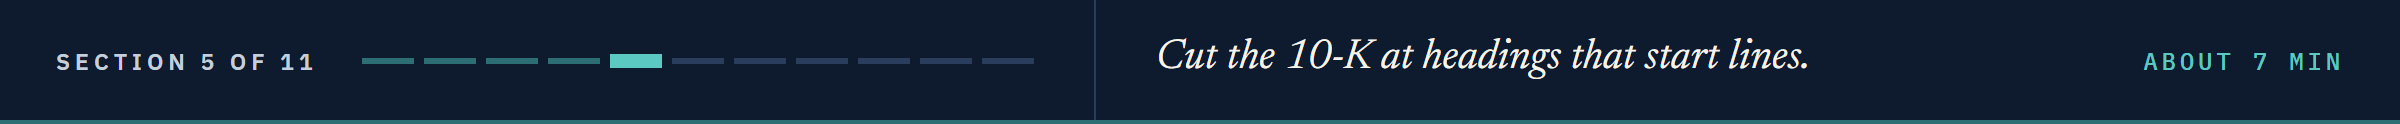

# A 10-K Cut into Its Items

Day 8 met Form 10-K, the annual report, and its Item 1A, Risk Factors.
The form has four **Parts** and 23 **items**, each under a heading that starts its own line, such as "ITEM 1A. Risk Factors".

**Predict 2**

Q. How many lines of the 10-K's text start with ITEM and an item code? Write down a number.

## Lines That Start With an Item

`re.IGNORECASE` matches capitals and lower case alike; with `re.MULTILINE` (Course 1), `^` matches at the start of every line.

In [21]:
# source text: quoted as published
# every line that starts with ITEM and a code, such as ITEM 7A, then the first two lines of Item 1A
line_starts = list(re.finditer(r"^ITEM (\d+[A-C]?)\b", ten_k_text, flags=re.IGNORECASE | re.MULTILINE))
print(len(line_starts), "lines |", [found.group(1) for found in line_starts])
print("lines 1 to 23 start from", line_starts[0].start(), "to", line_starts[22].start(), "| line 24 at", line_starts[23].start())
for found in [line_starts[1], line_starts[24]]:
    print(found.start(), ten_k_text[found.start():ten_k_text.find("\n", found.start())])
tenk_source()

46 lines | ['1', '1A', '1B', '1C', '2', '3', '4', '5', '6', '7', '7A', '8', '9', '9A', '9B', '9C', '10', '11', '12', '13', '14', '15', '16', '1', '1A', '1B', '1C', '2', '3', '4', '5', '6', '7', '7A', '8', '9', '9A', '9B', '9C', '10', '11', '12', '13', '14', '15', '16']
lines 1 to 23 start from 4586 to 5808 | line 24 at 5879
4605 ITEM 1A. Risk Factors 11
53289 ITEM 1A. Risk Factors
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.


46 lines, the 23 items twice: 23 contents lines ending in a page number, then 23 headings from character 5,879.

As Day 1 met in the indenture, the contents copy of a heading comes first.

## `split_items`

`re.escape(code)` makes the full stop in a code match only a full stop, so "2.04" matches only "2.04".
`\b` after the code keeps "ITEM 1" off "ITEM 1A" and "ITEM 10".
Working back from the last item, each heading is the last line start before the next item's, so every contents copy is passed over.

In [22]:
# from the last item back to the first: each starts at its last line start before the next item's, and its body follows its heading line
def split_items(text, items):
    """A filing's items, each cut at the last line start before the next item's: item, start, end, text, words."""
    rows, end = [], len(text)
    for item in items[::-1]:
        starts = [found.start() for found in re.finditer(rf"^ITEM {re.escape(item)}\b", text, flags=re.IGNORECASE | re.MULTILINE)]
        start = [where for where in starts if where < end][-1]
        body = text[text.find("\n", start):end].strip()
        rows.append({"item": item, "start": start, "end": end, "text": body, "words": len(body.split())})
        end = start
    return pd.DataFrame(rows[::-1])

**Predict 3**

Q. Sketch the words in each of the 23 items as bars, in the form's order. Which items are long, and which hold a line or less?

## The 10-K, Cut

In [23]:
# the form's 23 items in order (Part I 1 to 4, Part II 5 to 9C, Part III 10 to 14, Part IV 15 and 16), then the 10-K cut into them
TEN_K_ITEMS = ["1", "1A", "1B", "1C", "2", "3", "4", "5", "6", "7", "7A", "8", "9", "9A", "9B", "9C",
               "10", "11", "12", "13", "14", "15", "16"]
items = split_items(ten_k_text, TEN_K_ITEMS)
print(items[["item", "start", "end", "words"]].to_string(index=False))
print(items["words"].sum(), "words in the items |", (items["words"] < 50).sum(), "items under 50 words")

item  start    end  words
   1   5879  53289   7312
  1A  53289  89826   5446
  1B  89826  89866      1
  1C  89866  98497   1175
   2  98497  99973    242
   3  99973 100125     20
   4 100125 100201      8
   5 100201 104771    694
   6 104771 104788      0
   7 104788 200575  14826
  7A 200575 204154    573
   8 204154 391956  29178
   9 391956 392208     25
  9A 392208 399789   1106
  9B 399789 400093     42
  9C 400093 400194      4
  10 400194 404952    704
  11 404952 405382     54
  12 405382 405799     47
  13 405799 406163     43
  14 406163 406702     77
  15 406702 419844   2041
  16 419844 422118    359
63977 words in the items | 9 items under 50 words


Item 8, the financial statements, holds 29,178 words and Item 7, management's discussion, 14,826.

Nine items hold under 50 words; Item 6 holds none, its heading reads "Reserved".

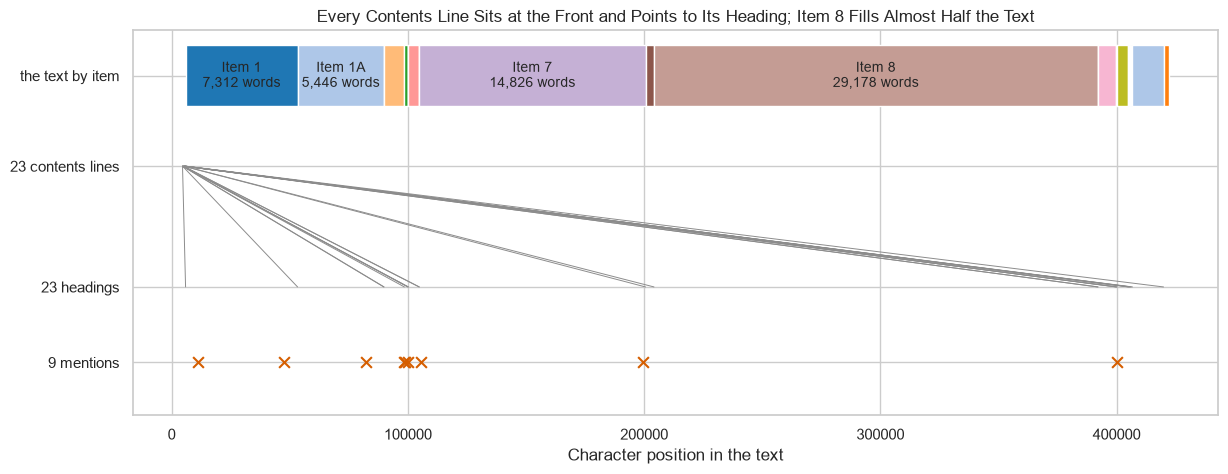

In [24]:
# the text as one bar by item (tab20, a set of 20 colours, so neighbours differ); beneath, the 23 contents lines joined to the 23 headings
# and the item mentions inside paragraphs as crosses
mentions = [found.start() for found in re.finditer(r"\bItem \d+[A-C]?\b", ten_k_text, flags=re.IGNORECASE)]
inside = [where for where in mentions if ten_k_text[where - 1] != "\n"]
fig, ax = plt.subplots(figsize=(14, 5))
ax.barh(3, items["end"] - items["start"], left=items["start"], height=0.8, color=sns.color_palette("tab20", 23), edgecolor="white")
for row in items[items["words"] > 4000].itertuples():
    ax.text((row.start + row.end) / 2, 3, f"Item {row.item}\n{row.words:,} words", ha="center", va="center", fontsize=10)
for copy, heading in zip(line_starts[:23], line_starts[23:]):
    ax.plot([copy.start(), heading.start()], [1.8, 0.2], color="0.55", linewidth=0.7)
ax.scatter(inside, [-0.8] * len(inside), marker="x", s=60, color="C3")
ax.set(yticks=[3, 1.8, 0.2, -0.8], yticklabels=["the text by item", "23 contents lines", "23 headings", f"{len(inside)} mentions"],
       xlabel="Character position in the text", ylim=(-1.5, 3.6))
ax.set_title("Every Contents Line Sits at the Front and Points to Its Heading; Item 8 Fills Almost Half the Text")
plt.show()

The 23 contents lines sit in the first 6,000 characters, and each fans out to its own heading.

Each cross is an item named inside a paragraph: `split_items` never cuts there, since none starts a line.

### Interpretation of the Cut

A **Pareto chart** (Course 5's Day 4) sorts the bars and adds their running share.

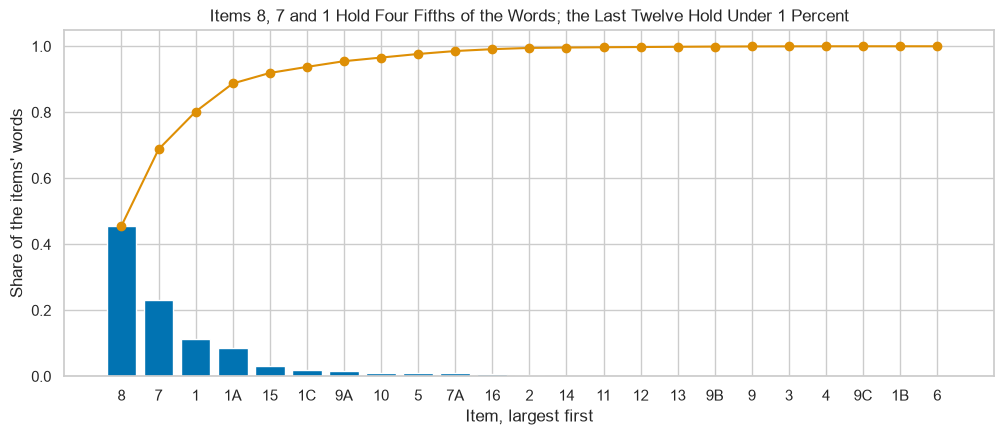

{'8': 0.4561, '7': 0.6878, '1': 0.8021} | the last twelve: 0.0088


In [25]:
# each item's share of the items' words, largest first, and the running share
share = items.set_index("item")["words"].sort_values(ascending=False) / items["words"].sum()
plt.figure(figsize=(12, 4.5))
plt.bar(share.index, share, color="C0")
plt.plot(share.index, share.cumsum(), color="C1", marker="o")
plt.xlabel("Item, largest first")
plt.ylabel("Share of the items' words")
plt.title("Items 8, 7 and 1 Hold Four Fifths of the Words; the Last Twelve Hold Under 1 Percent")
plt.show()
print(share.cumsum().round(4).head(3).to_dict(), "| the last twelve:", round(share.tail(12).sum(), 4))

Item 8 holds 0.4561 of the items' words, Items 8 and 7 0.6878, and with Item 1 0.8021.

An item's length describes how the filer wrote this 10-K, nothing more.

## Mentions Inside Paragraphs

In [26]:
# source text: quoted as published
# every Item and a code anywhere in the text, and each one inside a paragraph in a window of 40 characters either side
print(len(mentions), "mentions |", len(inside), "inside a paragraph")
for where in inside:
    print(where, "|", ten_k_text[where - 40:where + 40].replace("\n", " / "))
tenk_source()

55 mentions | 9 inside a paragraph
11258 | ancial statements presented in Part II, Item 8. / As of December 31, 2025, we oper
47662 | th the Risk Factors included in Part I, Item 1A of this Form 10-K, could affect 
82138 | ancial statements presented in Part II, Item 8, contains further disclosure rega
98146 | aterially affect the Company. Refer to "Item 1A. Risk Factors" in this annual re
98622 | f our properties is provided in Part I, Item 1, Business - Properties, and is in
100003 | lle OTBs. / ITEM 3. Legal Proceedings / See Item 8 of Part II, "Financial Statements
105411 | tted from this MD&A and may be found in Item 7. Management's Discussion and Anal
199448 | ancial statements presented in Part II, Item 8, for an aggregate purchase price 
400062 | , 2025, as such terms are defined under Item 408(a) of Regulation S-K. / ITEM 9C. 
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908.


55 mentions: the 46 line starts and 9 cross-references inside paragraphs; Item 3's whole body is one.

"Item 408(a) of Regulation S-K" names a rule, not an item of this form.

## Your Turn: Pick an Item

In [27]:
# the text as a page of 100-character squares, 60 to a row: the item you pick dark, the rest of the text pale, the page's empty end white
def draw_item(item):
    row = items.set_index("item").loc[item]
    cells = np.arange(0, len(ten_k_text), 100)
    shade = np.where((cells + 100 > row["start"]) & (cells < row["end"]), 1.0, 0.25)
    grid = np.concatenate([shade, np.zeros(71 * 60 - len(shade))]).reshape(71, 60)
    print(f"Item {item}: characters {row['start']:,} to {row['end']:,}, {row['words']:,} words")
    fig, ax = plt.subplots(figsize=(5, 6))
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=1.3, aspect="auto")
    ax.set(xticks=[], yticks=[], xlabel="Each square is 100 characters, read left to right, top to bottom")
    ax.set_title(f"Item {item} in the Text")
    plt.show()


interact(draw_item, item=TEN_K_ITEMS);

interactive(children=(Dropdown(description='item', options=('1', '1A', '1B', '1C', '2', '3', '4', '5', '6', '7…

Item 1A: characters 53,289 to 89,826, 5,446 words


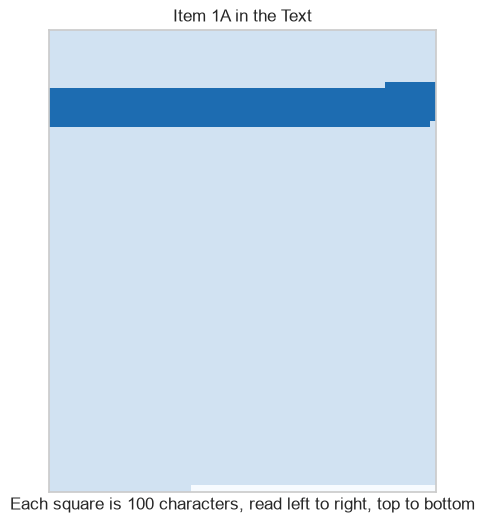

In [28]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_item("1A")

## The Start of Item 1A

In [29]:
# source text: quoted as published
# the first 300 characters of Item 1A's body
print(items.set_index("item").loc["1A", "text"][:300])
tenk_source("1A")

In addition to the other information contained in this report on Form 10-K, the following Risk Factors should be considered carefully in evaluating our business.
If any of the following risks actually occurs, our business, financial condition and results of operations could be materially and adverse
Source: Boyd Gaming Corporation, Form 10-K for the fiscal year ended December 31, 2025, filed 2026-02-20, accession 0001437749-26-004908, Item 1A.


Day 8's 18 Boyd risk factors were cut from this item by the course's tool.

**23 of 23 found, every contents copy and every mention passed over.**

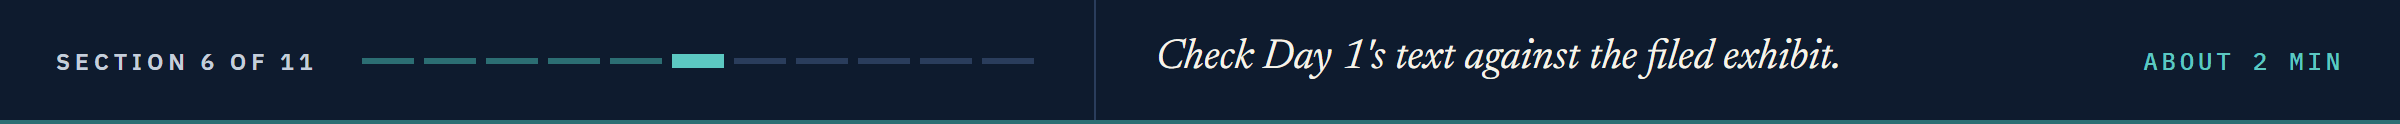

# The Indenture Every Earlier Day Read

## The Exhibit as Text

EDGAR wraps each document of a filing in **EDGAR's document wrapper**: `<DOCUMENT>`, its type, its place in the filing and its file name.

In [30]:
# source text: quoted as published
# the exhibit's first 120 bytes, then html_to_text against Day 1's .txt
print(exhibit_bytes[:120])
exhibit_text = html_to_text(exhibit_bytes)
print("the same text as Day 1's .txt:", exhibit_text == stored, "|", len(exhibit_text), "characters |", len(exhibit_text.split()), "words")
print(exhibit_text.split("\n")[0])
boyd_source()

b'<DOCUMENT>\n<TYPE>EX-4.1\n<SEQUENCE>2\n<FILENAME>d185267dex41.htm\n<DESCRIPTION>EX-4.1\n<TEXT>\n<HTML><HEAD>\n<TITLE>EX-4.1</TI'
the same text as Day 1's .txt: True | 392021 characters | 63595 words
EX-4.1 2 d185267dex41.htm EX-4.1
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


`html_to_text` of the exhibit as filed is the `.txt` every earlier day read, character for character.

The wrapper's words are its first line.

## `get_text` Alone on the Exhibit

In [31]:
# source text: quoted as published
# get_text alone on the exhibit: characters and lines, the same text or not, and the first lines of its contents
exhibit_soup = BeautifulSoup(exhibit_bytes, "html.parser")
plain_exhibit = normalize_text(exhibit_soup.get_text())
print(len(plain_exhibit), "characters |", plain_exhibit.count("\n") + 1, "lines against", stored.count("\n") + 1,
      "| the same text:", plain_exhibit == stored, "|", len(exhibit_soup.find_all("table")), "tables")
start = plain_exhibit.find("Section 1.01.")
print(plain_exhibit[start:start + 60].split("\n"))
boyd_source()

392015 characters | 3801 lines against 1714 | the same text: False | 147 tables
['Section 1.01.', 'Definitions', '1', 'Section 1.02.', 'Other Definitions', '']
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


`get_text` alone gives 3,801 lines against 1,714: the contents is a table, and each of its cells lands on a line of its own.

## Two Documents Side by Side

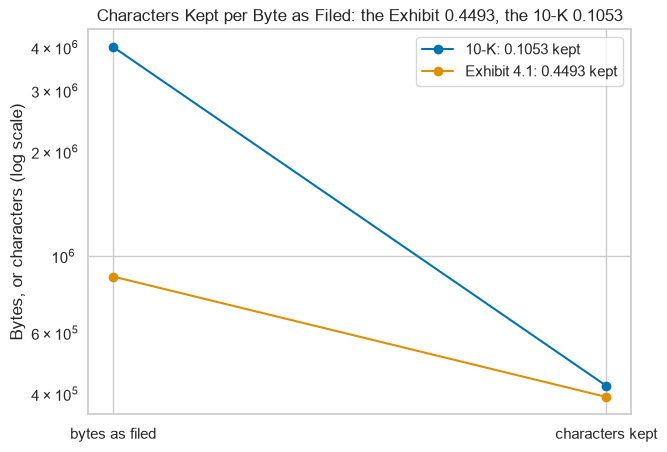

In [32]:
# bytes as filed against characters kept, the two documents on a log axis
kept = pd.DataFrame({"bytes as filed": [len(ten_k_bytes), len(exhibit_bytes)], "characters kept": [len(ten_k_text), len(exhibit_text)]},
                    index=["10-K", "Exhibit 4.1"])
plt.figure(figsize=(7, 5))
for name, row in kept.iterrows():
    plt.plot([0, 1], row, marker="o", label=f"{name}: {row.iloc[1] / row.iloc[0]:.4f} kept")
plt.xticks([0, 1], kept.columns)
plt.yscale("log")
plt.ylabel("Bytes, or characters (log scale)")
plt.legend()
plt.title("Characters Kept per Byte as Filed: the Exhibit 0.4493, the 10-K 0.1053")
plt.show()

The exhibit is plain HTML with no tagged facts, so it keeps almost half a character per byte.

The 10-K keeps about a tenth: most of its bytes are markup and tagged facts.

**Every indenture number since Day 1 is `html_to_text` of the filed exhibit.**

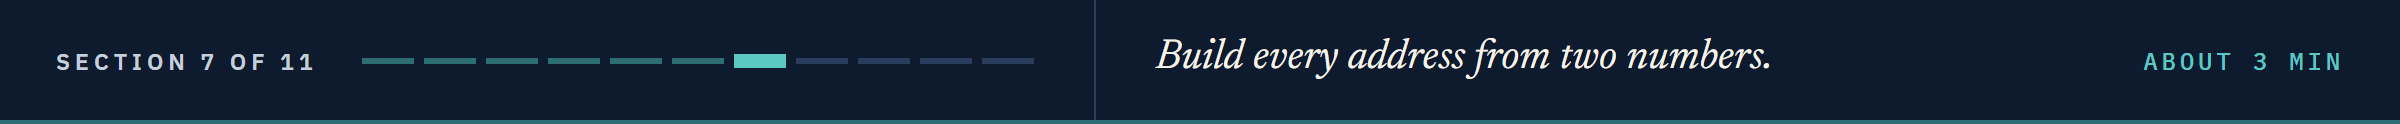

# EDGAR's Addresses

## Two Numbers Per Filing

Day 3's file named every filing by two numbers: the company's CIK and the filing's accession number.
**EDGAR**, the SEC's filing system, builds every address from them.
`:010d` writes a whole number with ten digits, zeros in front.

In [33]:
# Boyd's CIK, and the accession numbers of the 10-K and of the 8-K that carried the indenture
CIK = 906553
TEN_K_ACCESSION = "0001437749-26-004908"
EXHIBIT_ACCESSION = "0001193125-21-185495"
print(f"{CIK:010d} |", TEN_K_ACCESSION.replace("-", ""), "|", EXHIBIT_ACCESSION.replace("-", ""))

0000906553 | 000143774926004908 | 000119312521185495


> STORY: How far back the addresses go.
> The SEC's page "Accessing EDGAR Data" says: "EDGAR started in 1994/1995."
> Source: U.S. Securities and Exchange Commission, https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data (read 2026-11-18)

## Building the Addresses

A company's **submissions JSON** lists its filings; a **filing folder** holds every document of one filing, listed in its `index.json`; **full-text search** finds filings by their words.
`quote` is Course 3's.

In [34]:
# the company's filings, the 10-K's folder and its list of files, the 10-K, the exhibit, and a full-text search for one month
SUBMISSIONS_URL = f"https://data.sec.gov/submissions/CIK{CIK:010d}.json"
FOLDER_URL = f"https://www.sec.gov/Archives/edgar/data/{CIK}/{TEN_K_ACCESSION.replace('-', '')}/"
TEN_K_URL = FOLDER_URL + "bgc20251121_10k.htm"
EXHIBIT_URL = f"https://www.sec.gov/Archives/edgar/data/{CIK}/{EXHIBIT_ACCESSION.replace('-', '')}/d185267dex41.htm"
SEARCH_URL = ("https://efts.sec.gov/LATEST/search-index?q=" + quote('"Triggering Events That Accelerate"')
              + "&forms=8-K&dateRange=custom&startdt=2022-02-01&enddt=2022-02-28")
for url in [SUBMISSIONS_URL, FOLDER_URL, FOLDER_URL + "index.json", TEN_K_URL, EXHIBIT_URL, SEARCH_URL]:
    print(url)

https://data.sec.gov/submissions/CIK0000906553.json
https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/
https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/index.json
https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/bgc20251121_10k.htm
https://www.sec.gov/Archives/edgar/data/906553/000119312521185495/d185267dex41.htm
https://efts.sec.gov/LATEST/search-index?q=%22Triggering%20Events%20That%20Accelerate%22&forms=8-K&dateRange=custom&startdt=2022-02-01&enddt=2022-02-28


Three hosts: data.sec.gov for submissions, www.sec.gov for the archive, efts.sec.gov for full-text search.

The CIK is padded to ten digits in the first and plain in the folder; the accession loses its dashes in the folder.

The search is the form the course's tool used for Day 3's sections, a month at a time.

## An Address in Its Parts

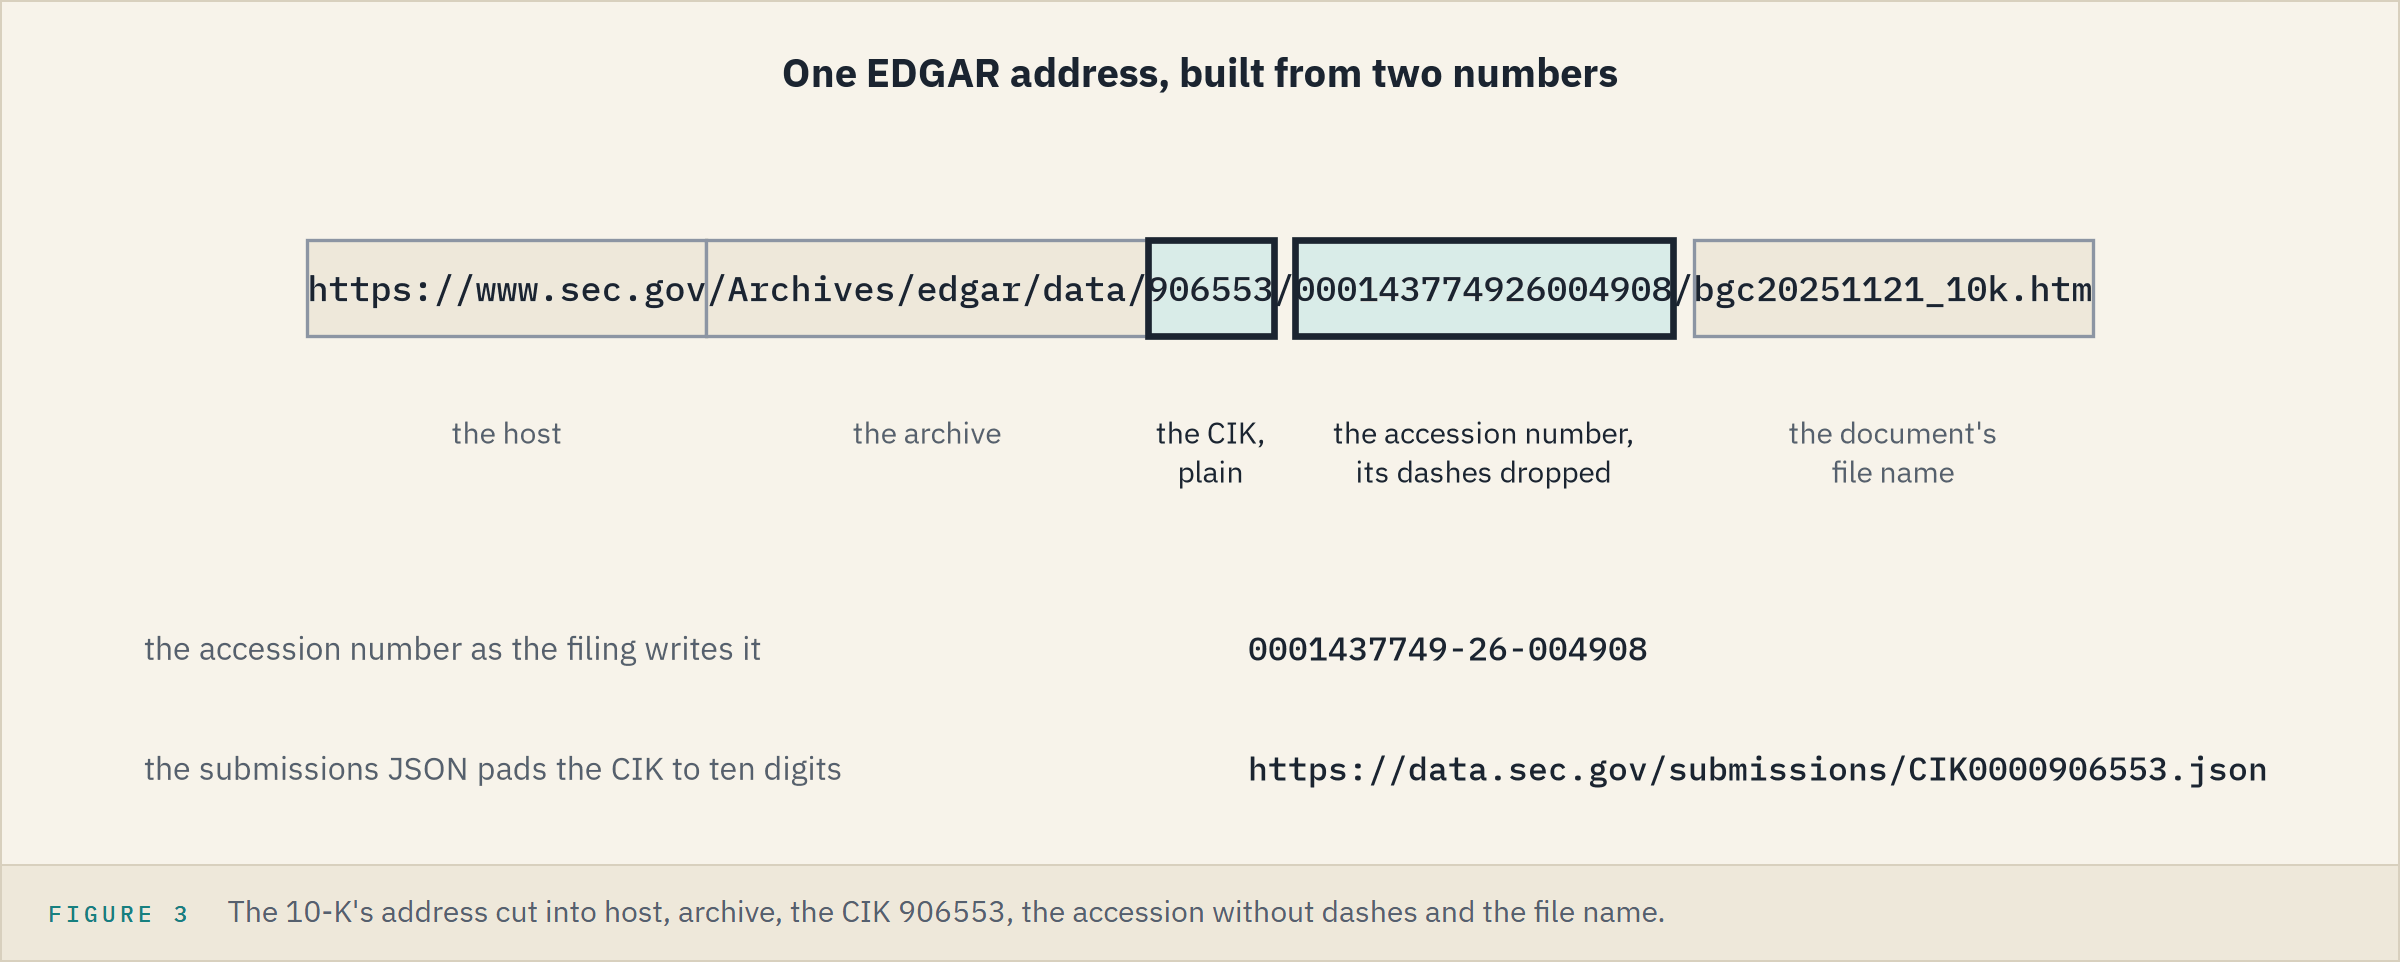

**Build every address from the two numbers, never retype one.**

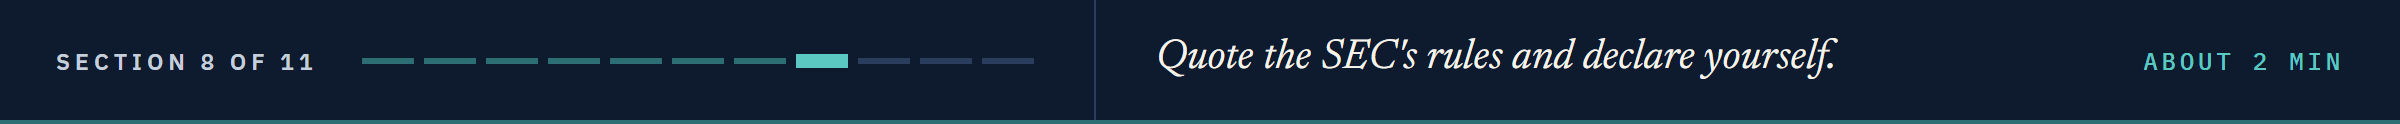

# The SEC's Rules for Programs

## The Rules, Quoted

The SEC's own pages, read 2026-11-18:

* "Accessing EDGAR Data" (https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data): "Please declare your user agent in request headers", with the sample `User-Agent: Sample Company Name AdminContact@<sample company domain>.com`, and "Current max request rate: 10 requests/second."
* "Privacy Information" (https://www.sec.gov/about/privacy-information): "Current guidelines limit users to a total of no more than 10 requests per second, regardless of the number of machines used to submit requests."
* The same page, under "Website Dissemination": "Information presented on sec.gov is considered public information and may be copied or further distributed by users of the web site without the SEC's permission."
* "EDGAR Application Programming Interfaces (APIs)" (https://www.sec.gov/search-filings/edgar-application-programming-interfaces): "These APIs do not require any authentication or API keys to access."

A **request header** is a line a program sends with its request, and the **User-Agent** header says who is asking.
Course 3 met a rate limit and its status, 429 (too many requests): the SEC keeps **fair access** the same way.

## `sec_headers`

In [35]:
# the one header the SEC asks for: who is asking, a name and an email
def sec_headers(name, email):
    """The request headers the SEC asks for: a User-Agent with a name and an email."""
    return {"User-Agent": f"{name} {email}"}


declared = sec_headers("Student Name", "student@example.com")
print(declared["User-Agent"])

Student Name student@example.com


**A program says who it is on every request.**

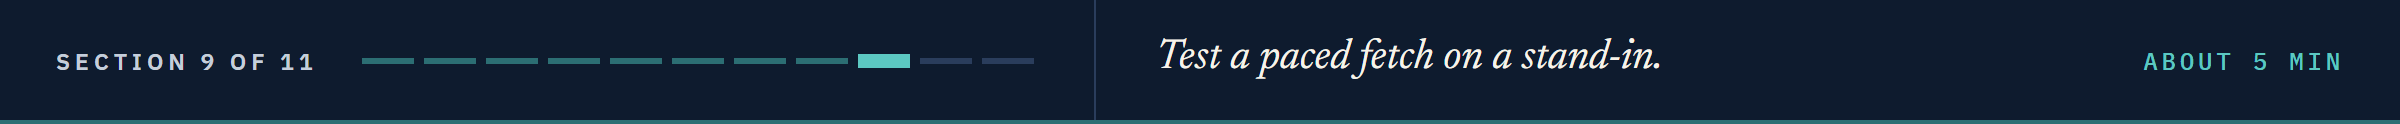

# A Fetch That Keeps the Rules

## A Stand-In Session

A **stand-in session** answers like sec.gov without the network, as Course 3's `FakeResponse` stood in for FRED.
Two small classes (Course 1): each answer is the next status in its list, and `sent` records what was sent.

In [36]:
# an answer: a status code, and the course's copy of the 10-K when the status is 200
class StandInResponse:
    def __init__(self, status_code):
        self.status_code = status_code
        self.content = ten_k_bytes if status_code == 200 else b""


# a session that answers each request with the next status in its list, and records what it was sent
class StandInSession:
    def __init__(self, statuses):
        self.statuses = list(statuses)
        self.sent = []

    def get(self, url, headers, timeout):
        self.sent.append((url, headers["User-Agent"]))
        return StandInResponse(self.statuses.pop(0))


session = StandInSession([200])
response = session.get(TEN_K_URL, headers=declared, timeout=60)
print(response.status_code, "|", len(response.content), "bytes |", session.sent)

200 | 4008734 bytes | [('https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/bgc20251121_10k.htm', 'Student Name student@example.com')]


## `edgar_get`

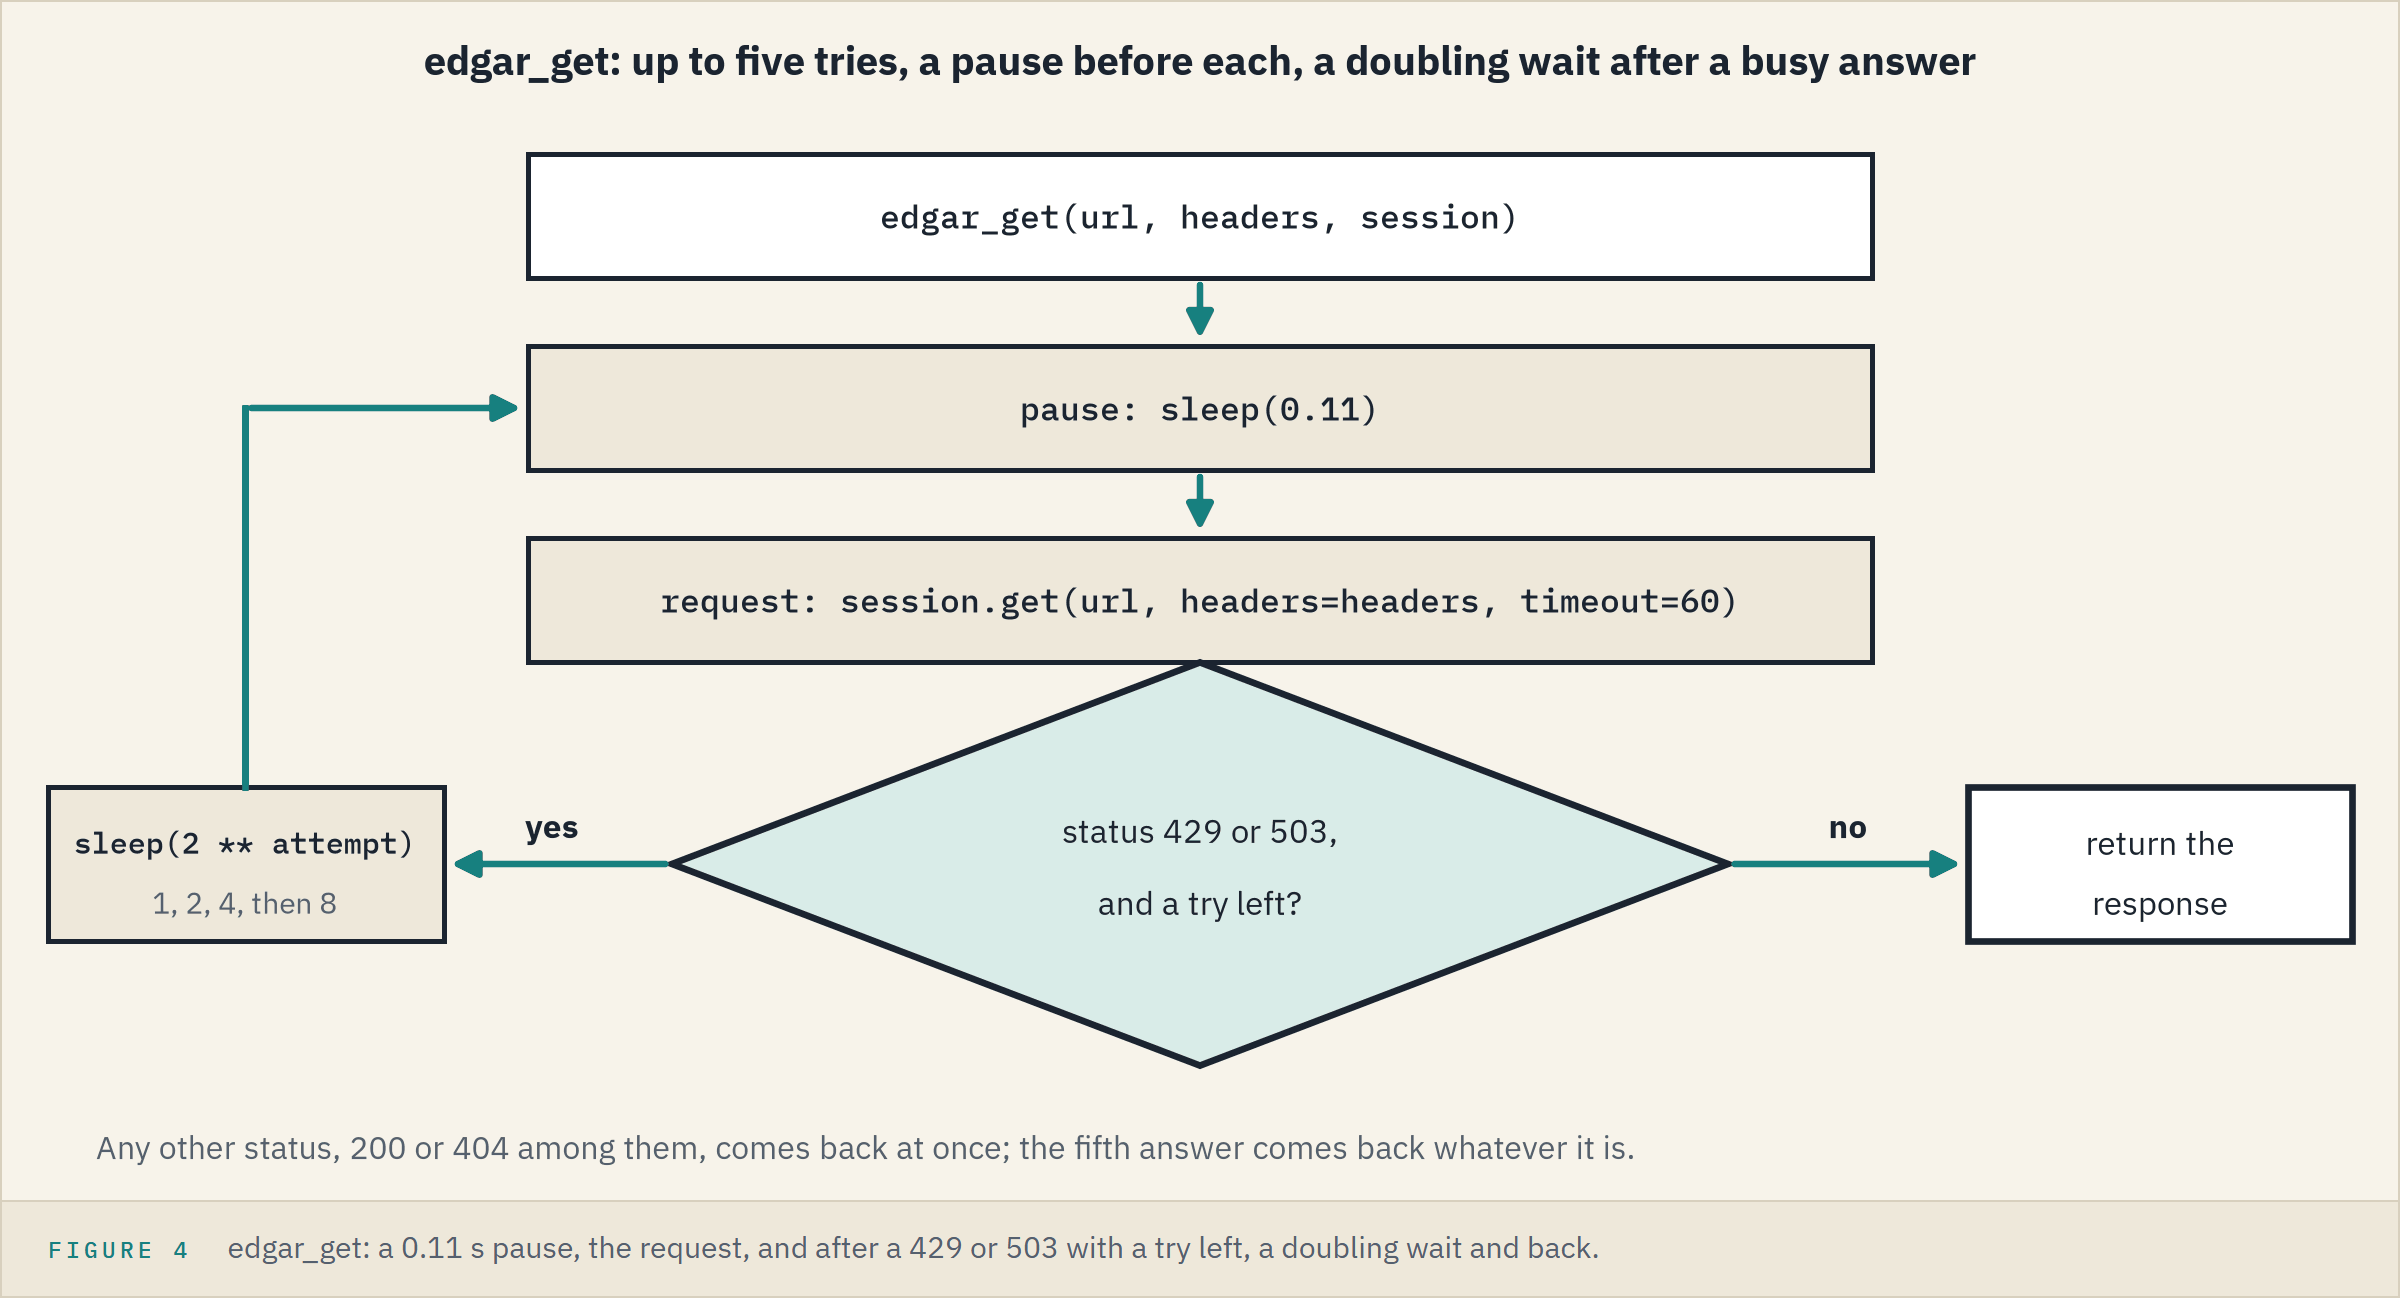

`edgar_get` pauses 0.11 seconds before every request, so it sends at most about 9.09 a second.
After a 429 or a 503 (the server is busy) it waits 1, 2, 4, then 8 seconds, doubling: that is **backoff**.
A 404 (no such page) comes back at once; `timeout=60` is Course 3's.
`sleep=time.sleep` passes **a function as an argument**: pass a list's `append` instead, and each pause is written down rather than waited.

In [37]:
# up to five tries, a pause before each; after a 429 or a 503 a wait that doubles; anything else comes back at once
def edgar_get(url, headers, session, sleep=time.sleep):
    """GET one sec.gov address, 0.11 s apart, trying again after a 429 or a 503."""
    for attempt in range(5):
        sleep(0.11)
        response = session.get(url, headers=headers, timeout=60)
        if response.status_code not in (429, 503) or attempt == 4:
            return response
        sleep(2 ** attempt)

**Predict 4**

Q. A stand-in answers 429 four times, then 200. How many seconds does `edgar_get` pause in all? Write down a number.

## Four Busy Answers

In [38]:
# four 429s, then a 200: every pause written into a list instead of waited
waits = []
busy = StandInSession([429, 429, 429, 429, 200])
response = edgar_get(TEN_K_URL, declared, busy, sleep=waits.append)
print(response.status_code, "after", len(busy.sent), "requests | pauses", waits, f"| {sum(waits):.2f} seconds")
print(Counter(agent for url, agent in busy.sent))

# a 404, a page that does not exist: one request, returned at once (waiting does not bring a missing page back)
missing, missing_waits = StandInSession([404]), []
print(edgar_get(TEN_K_URL + "x", declared, missing, sleep=missing_waits.append).status_code, "after", len(missing.sent), "request | pauses", missing_waits)

200 after 5 requests | pauses [0.11, 1, 0.11, 2, 0.11, 4, 0.11, 8, 0.11] | 15.55 seconds
Counter({'Student Name student@example.com': 5})
404 after 1 request | pauses [0.11]


15.55 seconds: 15 of backoff and 0.55 of pauses, and every request said who it was.

The 404 came back after one request: no wait brings a missing page back.

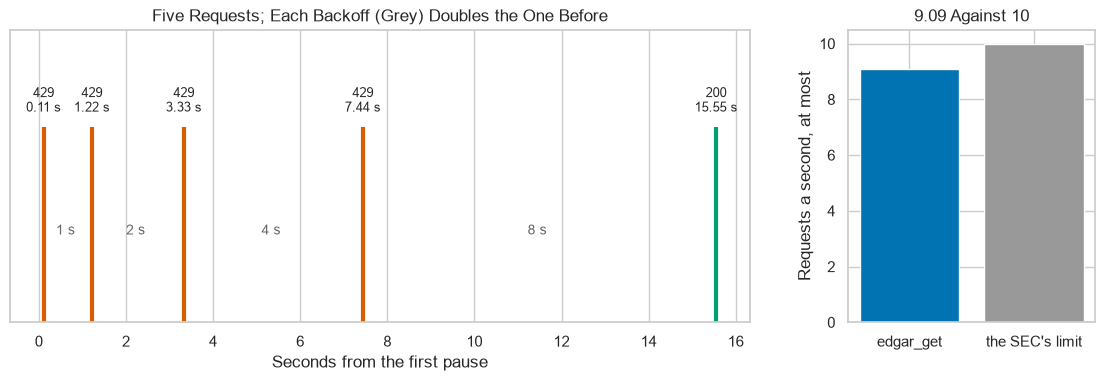

In [39]:
# the five requests on a time line, each backoff written between them, and the rate against the SEC's 10 a second
sent_at = np.cumsum(waits)[::2]
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 3.8), width_ratios=[3, 1])
left.vlines(sent_at, 0, 1, color=["C3"] * 4 + ["C2"], linewidth=3)
for at, status, wait in zip(sent_at, [429, 429, 429, 429, 200], [1, 2, 4, 8, 0]):
    left.text(at, 1.08, f"{status}\n{at:.2f} s", ha="center", fontsize=9)
    left.text(at + wait / 2, 0.45, f"{wait} s" if wait else "", ha="center", fontsize=10, color="0.4")
left.set(yticks=[], ylim=(0, 1.5), xlabel="Seconds from the first pause", title="Five Requests; Each Backoff (Grey) Doubles the One Before")
right.bar(["edgar_get", "the SEC's limit"], [1 / 0.11, 10], color=["C0", "0.6"])
right.set(ylabel="Requests a second, at most", title="9.09 Against 10")
plt.show()

## The Request Cell

`requests.Session()` keeps one connection for many requests, and `response.raise_for_status()` (Course 3) stops on an error status.
Here the switch is off, so the course's copy is read and nothing is sent.

In [40]:
# the switch: off here, so nothing leaves this notebook
FETCH_LIVE = False
if FETCH_LIVE:
    response = edgar_get(TEN_K_URL, declared, requests.Session())
    response.raise_for_status()
    filed = response.content
else:
    filed = Path(data_file("course7_boyd_10k_2025.htm")).read_bytes()
print("A live run sends: GET", TEN_K_URL, "| bytes:", len(filed), "| the course's copy:", filed == ten_k_bytes)

A live run sends: GET https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/bgc20251121_10k.htm | bytes: 4008734 | the course's copy: True


**The same bytes either way; the switch decides who sends.**

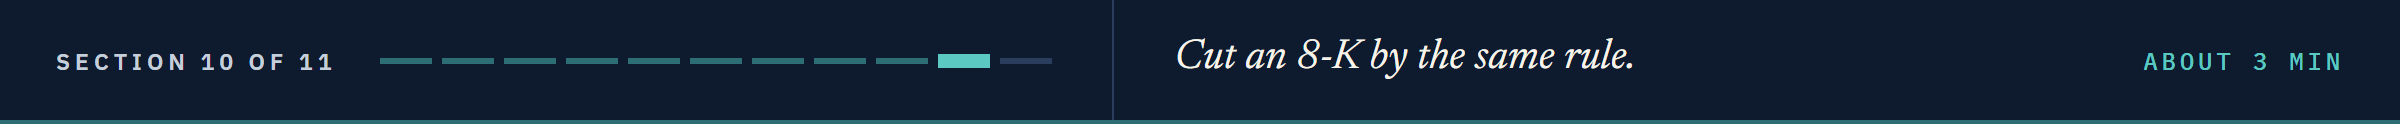

# Items of an 8-K

## Two Sections of One Filing

One 2022 filing holds two items; each heading goes back in Day 3's form: "Item", the code and the SEC's title.

In [41]:
# source text: quoted as published
# one filing's two sections, each heading put back, then joined into one text
filing = eightk[eightk["accession"] == "0001104659-22-017364"]
rebuilt = "\n".join("Item " + filing["item"] + " " + filing["item_title"] + "\n" + filing["text"])
print(filing[["filed", "item", "words"]].to_string(index=False), "|", len(rebuilt), "characters")

# the Item 2.03 body as stored
row = filing[filing["item"] == "2.03"].iloc[0]
print(normalize_text(row["text"]))
section_source(row)

     filed item  words
2022-02-10 1.01    157
2022-02-10 2.03     21 | 1220 characters
The information contained in Item 1.01 of this current report on Form 8-K is incorporated by reference in this Item 2.03.
Source: Golub Capital BDC 3, Inc., Form 8-K filed 2022-02-10, accession 0001104659-22-017364, Item 2.03, https://www.sec.gov/Archives/edgar/data/1715268/000110465922017364/tm225978d1_8k.htm


**Predict 5**

Q. Split the rebuilt text at every "Item" followed by a code such as 1.01. How many pieces come back? Write down a number.

## A Split at Every Mention

`re.split` is Day 5's: it cuts a text wherever a pattern matches.

In [42]:
# re.split at every Item and a code: the pieces' lengths, and where each match starts
pieces = re.split(r"Item \d\.\d\d", rebuilt)
matches = [found.start() for found in re.finditer(r"Item \d\.\d\d", rebuilt)]
print(len(pieces), "pieces of", [len(piece) for piece in pieces], "characters | matches at", matches)

5 pieces of [0, 966, 144, 73, 1] characters | matches at [0, 975, 1128, 1210]


A match at position 0 leaves an empty first piece.

Two of the four matches sit inside the 2.03 body, so two sections come back as five pieces.

## `split_items` on the 8-K

In [43]:
# the same function with the 8-K's own items: two rows, and the bodies against the stored sections
eight_k_items = split_items(rebuilt, ["1.01", "2.03"])
print(eight_k_items[["item", "start", "end", "words"]].to_string(index=False))
print("the bodies are the stored sections:", eight_k_items["text"].tolist() == filing["text"].tolist())

item  start  end  words
1.01      0  975    157
2.03    975 1220     21
the bodies are the stored sections: True


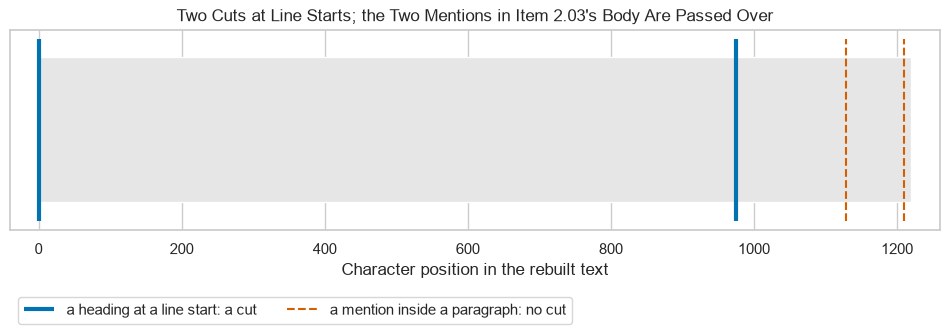

In [44]:
# the rebuilt text as one bar: the two line-start cuts solid, the two mentions inside the 2.03 body dashed
plt.figure(figsize=(12, 2.6))
plt.barh(0, len(rebuilt), color="0.9")
plt.vlines(eight_k_items["start"], -0.5, 0.5, color="C0", linewidth=3, label="a heading at a line start: a cut")
plt.vlines([where for where in matches if where not in eight_k_items["start"].tolist()], -0.5, 0.5, color="C3", linestyles="--", label="a mention inside a paragraph: no cut")
plt.yticks([])
plt.xlim(-40, len(rebuilt) + 40)
plt.xlabel("Character position in the rebuilt text")
plt.legend(loc="upper left", bbox_to_anchor=(0, -0.3), ncols=2)
plt.title("Two Cuts at Line Starts; the Two Mentions in Item 2.03's Body Are Passed Over")
plt.show()

**An 8-K is cut by the same rule, with its own item list.**

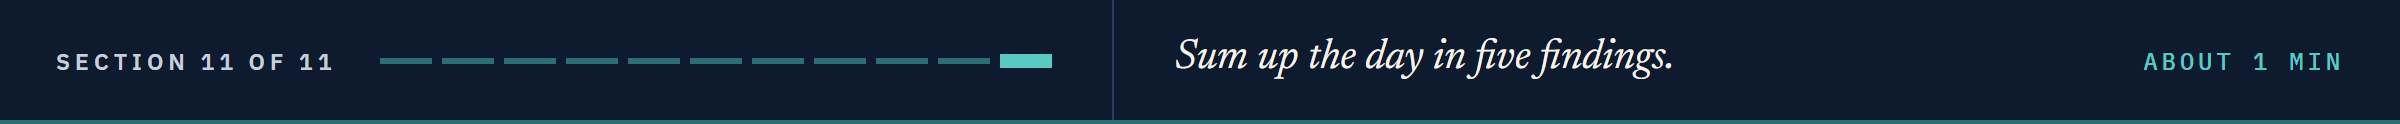

# Insights and Conclusion

The 10-K's 4,008,734 bytes hold 422,118 characters of text; the hidden header alone is 387,293 bytes.

46 lines start with an item; `split_items` keeps the 23 headings and passes over the contents and 9 mentions.

Item 8 holds 0.4561 of the items' words.

`html_to_text` of the filed exhibit is the `.txt` every earlier day read.

Every address comes from two numbers, every request declares a User-Agent, and four 429s cost 15.55 seconds, never waited.

**Ask within the rules, keep the words, cut at line starts, then check the copy.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Build EDGAR's addresses from a CIK and an accession number.
* Write a fetch that declares a User-Agent, paces its requests and backs off, and test it on a stand-in.
* Turn a filing's HTML into one paragraph per line with BeautifulSoup, its hidden header removed.
* Cut a 10-K or an 8-K into its items at headings that start a line.
* Check a stored text against the document it came from.

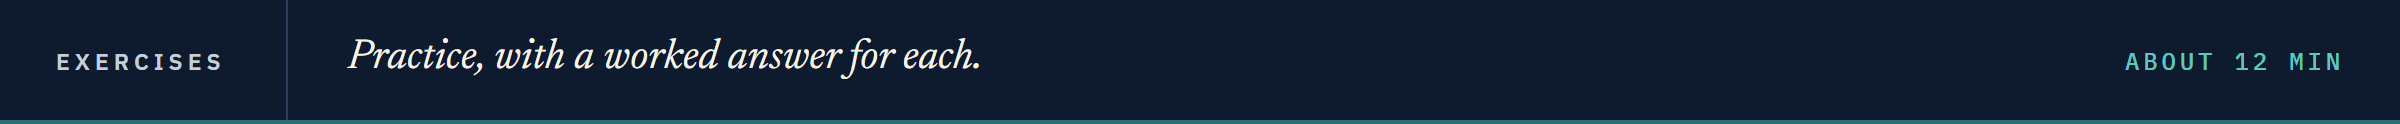

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Item 7 Against Item 1A**

Q. How many words of Item 7 are there for each word of Item 1A? Store the ratio in `ex1_ratio`.

In [46]:
# your code here
ex1_ratio = ...

In [47]:
check("Exercise 1 Item 7's words per word of Item 1A", ex1_ratio, 2.7223650385604112)

Exercise 1 Item 7's words per word of Item 1A: not attempted yet


### Exercise 2

**The Contents' Own List**

Q. Read the item codes of the table of contents from the line starts before Item 1's heading, in order, into the list `ex2_toc`.

In [48]:
# your code here
ex2_toc = ...

In [49]:
check("Exercise 2 the contents' item codes", ex2_toc, ["1", "1A", "1B", "1C", "2", "3", "4", "5", "6", "7", "7A", "8", "9", "9A",
                                                        "9B", "9C", "10", "11", "12", "13", "14", "15", "16"])

Exercise 2 the contents' item codes: not attempted yet


### Exercise 3

**A Function for the Folder**

Q. Write `accession_folder(cik, accession)`, which returns a filing folder's address from a CIK and an accession number written with dashes. Store the 10-K's folder in `ex3_folder`.

In [50]:
# your code here
ex3_folder = ...

In [51]:
check("Exercise 3 the 10-K's folder", ex3_folder, "https://www.sec.gov/Archives/edgar/data/906553/000143774926004908/")

Exercise 3 the 10-K's folder: not attempted yet


### Exercise 4: AI check

**Who Is Asking**

You asked an AI assistant for a function that fetches a filing for a named person.
This came back.
Predict what the session receives, run it on a stand-in, then find the one bug.

In [52]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def fetch_filing(url, name, email, session):
    """Fetch one filing from sec.gov for the named person (the pages are public, so the default agent will do)."""
    headers = {"User-Agent": "python-requests", "Accept": "text/html"}
    return session.get(url, headers=headers, timeout=60)

In [53]:
# what a stand-in receives, beside the User-Agent the SEC asks for
check_session = StandInSession([200])
fetch_filing(TEN_K_URL, "Student Name", "student@example.com", check_session)
print("sent:", check_session.sent[0][1], "| asked for:", sec_headers("Student Name", "student@example.com")["User-Agent"])

sent: python-requests | asked for: Student Name student@example.com


Q. Fix the one wrong idea, run the fixed function on a fresh stand-in, and store the User-Agent it sends in `ex4_agent`.

In [54]:
# your code here
ex4_agent = ...

In [55]:
check("Exercise 4 the User-Agent the fixed function sends", ex4_agent, "Student Name student@example.com")

Exercise 4 the User-Agent the fixed function sends: not attempted yet


To fetch for real, copy the request cell into a script of your own, put your own name and email in `sec_headers`, and set the switch to True there.

## Congratulations!

You took a filing from EDGAR to text a program can count, and checked every step.
You stripped four megabytes of markup down to 422,118 characters with a function built from five small steps.
You cut a 10-K into its 23 items without one wrong cut, and showed that every indenture number since Day 1 came from the exhibit as filed.
You wrote a fetch that says who it is and keeps the SEC's rules, without sending one request.
On Day 10 the 2025 sections open at last, once.

[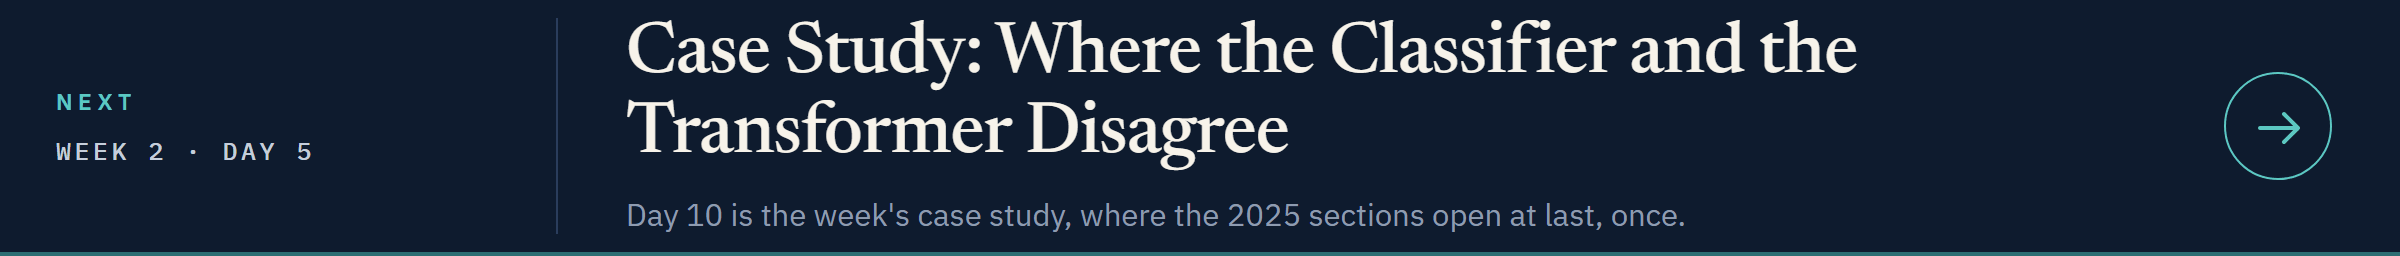](../day5/10_case_study_where_the_classifier_and_the_transformer_disagree.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week2/day5/10_case_study_where_the_classifier_and_the_transformer_disagree.ipynb)